In [1]:
import json
import os
from pathlib import Path
from sqlalchemy import create_engine, text
import pandas as pd
import numpy as np
from tqdm.notebook import tqdm

# 1. 환경변수 파일(.env) 로드
CURRENT_DIR = Path.cwd()
ENV_PATH = CURRENT_DIR / "geo.env"

if ENV_PATH.exists():
    with open(ENV_PATH, "r", encoding="utf-8-sig") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            if "=" in line:
                key, val = line.split("=", 1)
                os.environ[key.strip()] = val.strip()

# 2. DB 연결 정보 추출 및 engine 생성
DB_USER = os.getenv("DB_USER")
DB_PASSWORD = os.getenv("DB_PASSWORD")
DB_HOST = os.getenv("DB_HOST")
DB_PORT = os.getenv("DB_PORT")
DB_NAME = os.getenv("DB_NAME")

ENGINE_URL = f"mysql+pymysql://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}"
engine = create_engine(ENGINE_URL)

#### text_ratio

In [3]:
with engine.connect() as conn:
    query = text("""
        SELECT
            brand_name,
            COUNT(DISTINCT page_id) AS total_pages,
            ROUND(AVG(page_text_len), 1) AS avg_text_len,
            ROUND(AVG(page_image_len), 1) AS avg_image_len,
            -- 각 페이지별 (본문 / (본문 + 이미지)) 비율의 평균을 계산
            ROUND(AVG(
                CASE 
                    WHEN (page_text_len + page_image_len) = 0 THEN 0
                    ELSE (page_text_len * 1.0) / (page_text_len + page_image_len)
                END
            ), 4) AS avg_text_ratio
        FROM (
            -- 1. 페이지(page_id)별 글자 수 선 집계
            SELECT 
                brand_name,
                page_id,
                SUM(CHAR_LENGTH(COALESCE(text_contents, ''))) AS page_text_len,
                SUM(CHAR_LENGTH(COALESCE(image_text, ''))) AS page_image_len
            FROM geo_db.raw_data_table
            GROUP BY brand_name, page_id
        ) sub
        GROUP BY brand_name
        ORDER BY avg_text_ratio DESC;
    """)
    text_ratio = conn.execute(query).mappings().fetchall()

df = pd.DataFrame(text_ratio)
df

,brand_name,total_pages,avg_text_len,avg_image_len,avg_text_ratio
0,Uniqlo,429,349.7,38.9,0.8369
1,메리엣,52,1181.5,636.4,0.7178
2,올라,125,644.5,281.0,0.7047
3,LF,2527,296.4,0.0,0.5904
4,자스민벨,280,744.2,582.2,0.5788
5,노드유,179,2888.5,761.9,0.5759
6,미니포에,100,467.0,506.4,0.5353
7,슈가파우더,377,364.6,470.2,0.4934
8,아이딜릭마켓,590,14.4,941.4,0.1606
9,루프온,282,290.7,1605.3,0.1498


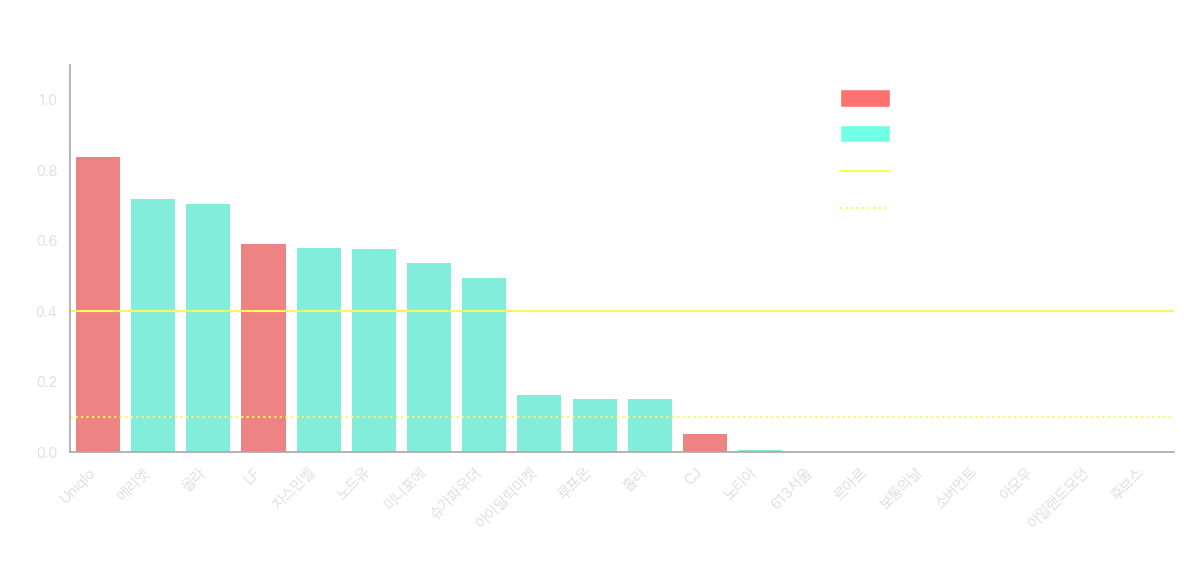

In [ ]:
import os
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.font_manager as fm
import seaborn as sns
import numpy as np

# Pretendard 폰트 로드
font_path = r'C:\Users\hkssn\바탕 화면\multicam\project_db\PretendardVariable.ttf'

if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)
    font_prop = fm.FontProperties(fname=font_path)
    font_name = font_prop.get_name()
    plt.rc('font', family=font_name)
else:
    plt.rc('font', family='Malgun Gothic')

plt.rcParams['axes.unicode_minus'] = False

enterprise_list = ['Uniqlo', 'CJ', 'LF', 'UNIQLO', 'cj', 'lf']
df['category'] = df['brand_name'].apply(lambda x: '대기업' if x in enterprise_list else '소상공인')

fig, ax = plt.subplots(figsize=(12, 6))
fig.patch.set_alpha(0.0)
ax.patch.set_alpha(0.0)

# 민트: #71FFE7 / 코랄: #FF7171
base_coral = mcolors.to_rgb('#FF7171')
base_mint = mcolors.to_rgb('#71FFE7')

colors = []
for _, row in df.iterrows():
    ratio = float(row['avg_text_ratio'])
    alpha = 0.65 + (ratio * 0.35)
    
    if row['category'] == '대기업':
        colors.append((*base_coral, alpha))
    else:
        colors.append((*base_mint, alpha))

sns.barplot(
    data=df,
    x='brand_name',
    y='avg_text_ratio',
    hue='brand_name',
    palette=colors,
    legend=False,
    edgecolor='none',
    ax=ax
)

# 임계치 점선
line_color = "#FAF761"
plt.axhline(0.4, color=line_color, linestyle='-', linewidth=1.5)
plt.axhline(0.1, color=line_color, linestyle='dotted', linewidth=1.5)

for p in ax.patches:
    height = p.get_height()
    if not np.isnan(height) and height > 0:
        ax.annotate(
            f'{height:.2f}',
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='bottom',
            xytext=(0, 1),
            textcoords='offset points',
            fontsize=11,
            fontweight='bold',
            color='#FFFFFF'
        )

ax.set_title('브랜드별 평균 본문 텍스트 비율', fontsize=24, pad=22, color='#FFFFFF', fontweight='bold')
ax.set_xlabel('브랜드명', fontsize=20, labelpad=12, color='#FFFFFF', fontweight='bold')
ax.set_ylabel('평균 텍스트 비율', fontsize=16, color='#FFFFFF', fontweight='bold')
ax.set_ylim(0, 1.1)

ax.spines['bottom'].set_color('#AAAAAA')
ax.spines['left'].set_color('#AAAAAA')
ax.tick_params(axis='x', colors='#E0E0E0', labelsize=11)
ax.tick_params(axis='y', colors='#E0E0E0', labelsize=10.5)
plt.xticks(rotation=45, ha='right')

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=(*base_coral, 1.0), label='대기업 (Uniqlo, CJ, LF)'),
    Patch(facecolor=(*base_mint, 1.0), label='소상공인 브랜드'),
    plt.Line2D([0], [0], color=line_color, linestyle='-', linewidth=1.5, label='Threshold (0.4)'),
    plt.Line2D([0], [0], color=line_color, linestyle='dotted', linewidth=1.5, label='Threshold (0.1)')
]
legend = ax.legend(
    handles=legend_elements, 
    loc='upper right', 
    fontsize=18, 
    frameon=False, 
    labelcolor='#FFFFFF'
)

sns.despine(top=True, right=True)
plt.grid(axis='y', linestyle='--', alpha=0.2, color='#FFFFFF')
plt.tight_layout()

plt.show()

#### keyword_stuffing

##### 1차

In [6]:
with engine.connect() as conn:
    query = text("""
        SELECT
            brand_name,
            product_name
        FROM
            geo_db.raw_data_table
    """)
    text_ratio = conn.execute(query).mappings().fetchall()

df = pd.DataFrame(text_ratio)
df

,brand_name,product_name
0,CJ,남성 쿨 원턱 와이드 트레이닝팬츠 PHG2PT1759
1,CJ,트레이닝 반바지 249PT262
2,CJ,남성 여성 커플 냉장고바지 쿨팬츠 8부 9부 아이스바지
3,CJ,캘빈클라인 에센셜 셋업 3종 세트 남여공용
4,CJ,7부 바지 스판 밴딩 냉장고 쿨링 아이스 냉감 칠부 츄리닝 트레이닝 팬츠
...,...,...
8758,Uniqlo,AIRism코튼T(스트라이프)
8759,Uniqlo,워셔블밀라노립크루넥스웨터
8760,Uniqlo,워셔블3D니트크루넥스웨터
8761,Uniqlo,드라이스트레치스웨트재킷


In [ ]:
import re
from kiwipiepy import Kiwi

kiwi = Kiwi()

def analyze_product_name(product_name: str) -> dict:
    if not product_name:
        return {
            "delimiters": [],
            "emojis": [],
            "unicodes": [],
            "stuffing_words": [],
            "pattern_count": 0,
            "nouns": [],
            "noun_count": 0
        }

    tokens = kiwi.tokenize(product_name)
    
    delimiters = []      # 구분자
    emojis = []          # 이모티콘 
    unicodes = []        # 유니코드 기호
    stuffing_words = []  # 감지된 스터핑 단어 (핏, 룩, 템)
    nouns = []           # 명사 전체 목록
    
    # 정규식 패턴 정의
    delim_pattern = re.compile(r'[/|\[\](),_.]')
    emoji_pattern = re.compile(
        r'[\U0001F600-\U0001F64F'  # Emoticons
        r'\U0001F300-\U0001F5FF'  # Symbols & Pictographs
        r'\U0001F680-\U0001F6FF'  # Transport & Map Symbols
        r'\U0001F1E0-\U0001F1FF'  # Flags
        r'\U00002702-\U000027B0'  # Dingbats
        r'\U0001F900-\U0001F9FF'  # Supplemental Symbols
        r'\U0001FA70-\U0001FAFF]'  # Symbols and Pictographs Extended
    )
    
    target_suffixes = ('핏', '룩', '템')

    for token in tokens:
        form = token.form
        tag = token.tag
        
        if delim_pattern.match(form) or tag in ['SF', 'SP', 'SS', 'SE', 'SO']:
            delimiters.append(form)
            
        elif tag == 'SW' or not form.isalnum():
            if emoji_pattern.search(form):
                emojis.append(form)
            else:
                unicodes.append(form)
                
        if tag.startswith('N'):
            nouns.append(form)
            if form.endswith(target_suffixes):
                stuffing_words.append(form)

    return {
        "delimiters": delimiters,
        "emojis": emojis,
        "unicodes": unicodes,
        "stuffing_words": stuffing_words,
        "pattern_count": len(stuffing_words),
        "nouns": nouns,
        "noun_count": len(nouns)
    }

In [ ]:
results = df['product_name'].apply(analyze_product_name)

df['delimiters_count'] = results.apply(lambda x: len(x['delimiters']))
df['delimiters_raw']   = results.apply(lambda x: x['delimiters'])
df['emojis_count']     = results.apply(lambda x: len(x['emojis']))
df['emojis_raw']       = results.apply(lambda x: x['emojis'])
df['unicodes_count']   = results.apply(lambda x: len(x['unicodes']))
df['unicodes_raw']     = results.apply(lambda x: x['unicodes'])
df['stuffing_count']   = results.apply(lambda x: x['pattern_count'])
df['stuffing_words']   = results.apply(lambda x: x['stuffing_words'])
df['noun_count']       = results.apply(lambda x: x['noun_count'])
df['nouns_raw']        = results.apply(lambda x: x['nouns'])

C:\Users\hkssn\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 47749 (\N{HANGUL SYLLABLE MYEONG}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\hkssn\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 49324 (\N{HANGUL SYLLABLE SA}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\hkssn\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 44060 (\N{HANGUL SYLLABLE GAE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\hkssn\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\hkssn\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 44396 (\N{HANGUL SYLLABLE 

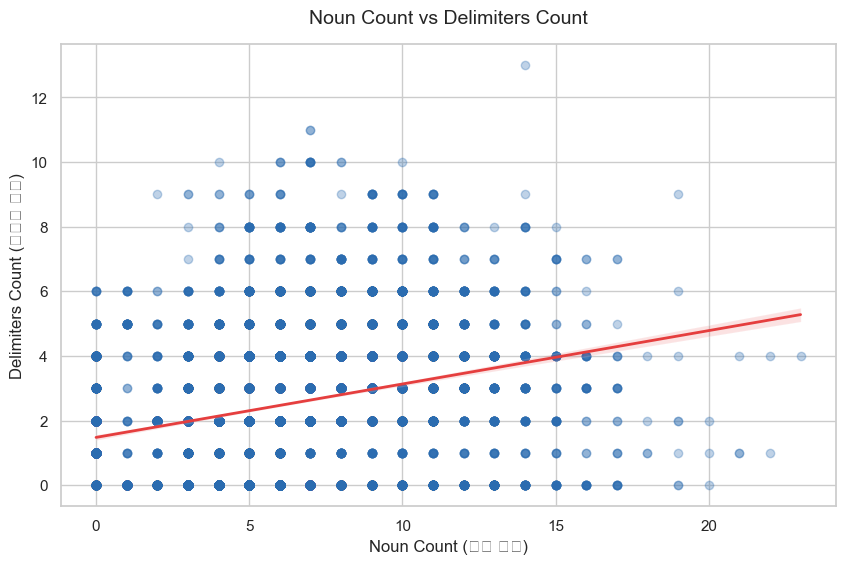

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rc('font', family='NanumGothic')
plt.rc('axes', unicode_minus=False)
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")
sns.regplot(
    data=df,
    x='noun_count',
    y='delimiters_count',
    scatter_kws={'alpha': 0.3, 'color': '#2b6cb0'},
    line_kws={'color': '#e53e3e', 'linewidth': 2}
)

plt.title('Noun Count vs Delimiters Count', fontsize=14, pad=15)
plt.xlabel('Noun Count (명사 개수)', fontsize=12)
plt.ylabel('Delimiters Count (구분자 개수)', fontsize=12)

plt.show()

In [ ]:
import scipy.stats as stats

pearson_corr, p_val_pearson = stats.pearsonr(df['noun_count'], df['delimiters_count'])
spearman_corr, p_val_spearman = stats.spearmanr(df['noun_count'], df['delimiters_count'])

print("=== 📊 상관계수 검정 결과 ===")
print(f"[Pearson]  상관계수(r): {pearson_corr:.4f}  |  p-value: {p_val_pearson:.4e}")
print(f"[Spearman] 상관계수(ρ): {spearman_corr:.4f}  |  p-value: {p_val_spearman:.4e}")

print("\n=== 💡 통계적 해석 ===")
if abs(pearson_corr) < 0.2:
    print("-> 상관계수가 0.2 미만으로, 두 변수 간에는 '상관관계가 거의 없다(무의미하다)'고 판단됩니다.")
elif abs(pearson_corr) < 0.4:
    print("-> 약한 상관관계가 존재합니다.")
else:
    print("-> 유의미한 상관관계가 존재합니다.")

if p_val_pearson < 0.05:
    print("-> p-value < 0.05 이므로, 통계적으로 유의미한 p-value를 가집니다 (단, 상관계수 절대값이 작아 실질적 영향력은 미비).")

=== 📊 상관계수 검정 결과 ===
[Pearson]  상관계수(r): 0.2831  |  p-value: 3.7236e-161
[Spearman] 상관계수(ρ): 0.3377  |  p-value: 1.0428e-232

=== 💡 통계적 해석 ===
-> 약한 상관관계가 존재합니다.
-> p-value < 0.05 이므로, 통계적으로 유의미한 p-value를 가집니다 (단, 상관계수 절대값이 작아 실질적 영향력은 미비).


In [ ]:
brand_means = df.groupby('brand_name')[
    ['delimiters_count', 'emojis_count', 'unicodes_count', 'stuffing_count']
].mean().round(2)

brand_means

,delimiters_count,emojis_count,unicodes_count,stuffing_count
brand_name,,,,
613서울,2.05,0.00,0.00,0.00
CJ,1.84,0.00,0.35,0.12
LF,3.07,0.00,0.16,0.06
Uniqlo,1.26,0.00,0.03,0.05
노드유,2.03,0.00,0.00,0.09
노티아,1.34,0.00,0.00,0.00
루프온,0.00,0.00,0.00,0.02
르아르,2.23,0.00,0.11,0.23
메리엣,2.54,0.00,0.04,0.04


In [ ]:
import re
from collections import Counter
from kiwipiepy import Kiwi
import pandas as pd

kiwi = Kiwi()

delim_pattern = re.compile(r'[/|\[\](),_.]')
emoji_pattern = re.compile(
    r'[\U0001F600-\U0001F64F\U0001F300-\U0001F5FF\U0001F680-\U0001F6FF'
    r'\U0001F1E0-\U0001F1FF\U00002702-\U000027B0\U0001F900-\U0001F9FF\U0001FA70-\U0001FAFF]'
)

summary_rows = []

for brand, group in df.groupby('brand_name'):
    total_products = len(group)
    total_tokens = 0
    
    pos_counts = {
        'noun': 0, 'verb': 0, 'modifier': 0, 'foreign': 0, 
        'number': 0, 'delimiter': 0, 'emoji': 0, 'unicode': 0, 
        'josa': 0, 'eomi': 0, 'affix': 0, 'etc': 0
    }

    for product_name in group['product_name'].dropna():
        tokens = kiwi.tokenize(product_name)
        
        for token in tokens:
            form = token.form
            tag = token.tag
            total_tokens += 1
            
            if delim_pattern.match(form) or tag in ['SF', 'SP', 'SS', 'SE', 'SO']:
                pos_counts['delimiter'] += 1
            elif tag == 'SW' or not form.isalnum():
                if emoji_pattern.search(form):
                    pos_counts['emoji'] += 1
                else:
                    pos_counts['unicode'] += 1
            elif tag.startswith('N') or tag == 'XSN':
                pos_counts['noun'] += 1
            elif tag.startswith('V') or tag in ['XSV', 'XSA']:
                pos_counts['verb'] += 1
            elif tag.startswith('M'):
                pos_counts['modifier'] += 1
            elif tag in ['SL', 'SH']:
                pos_counts['foreign'] += 1
            elif tag == 'SN':
                pos_counts['number'] += 1
            elif tag.startswith('J'):
                pos_counts['josa'] += 1
            elif tag.startswith('E'):
                pos_counts['eomi'] += 1
            elif tag.startswith('X'):
                pos_counts['affix'] += 1
            else:
                pos_counts['etc'] += 1

    # 요약 데이터
    row = {
        "brand_name": brand,
        "product_count": total_products,
        "avg_token_count": round(total_tokens / total_products, 2) if total_products > 0 else 0.0,
        
        # 1. 품사별 상품당 평균 개수
        "avg_noun_count": round(pos_counts['noun'] / total_products, 2) if total_products > 0 else 0.0,
        "avg_verb_count": round(pos_counts['verb'] / total_products, 2) if total_products > 0 else 0.0,
        "avg_modifier_count": round(pos_counts['modifier'] / total_products, 2) if total_products > 0 else 0.0,
        "avg_foreign_count": round(pos_counts['foreign'] / total_products, 2) if total_products > 0 else 0.0,
        "avg_number_count": round(pos_counts['number'] / total_products, 2) if total_products > 0 else 0.0,
        "avg_delimiter_count": round(pos_counts['delimiter'] / total_products, 2) if total_products > 0 else 0.0,
        "avg_emoji_count": round(pos_counts['emoji'] / total_products, 2) if total_products > 0 else 0.0,
        "avg_unicode_count": round(pos_counts['unicode'] / total_products, 2) if total_products > 0 else 0.0,
        "avg_josa_count": round(pos_counts['josa'] / total_products, 2) if total_products > 0 else 0.0,
        "avg_eomi_count": round(pos_counts['eomi'] / total_products, 2) if total_products > 0 else 0.0,
        "avg_affix_count": round(pos_counts['affix'] / total_products, 2) if total_products > 0 else 0.0,
        "avg_etc_count": round(pos_counts['etc'] / total_products, 2) if total_products > 0 else 0.0,

        # 2. 전체 품사 점유 비율
        "noun_pct": round((pos_counts['noun'] / total_tokens) * 100, 2) if total_tokens > 0 else 0.0,
        "verb_pct": round((pos_counts['verb'] / total_tokens) * 100, 2) if total_tokens > 0 else 0.0,
        "modifier_pct": round((pos_counts['modifier'] / total_tokens) * 100, 2) if total_tokens > 0 else 0.0,
        "foreign_pct": round((pos_counts['foreign'] / total_tokens) * 100, 2) if total_tokens > 0 else 0.0,
        "number_pct": round((pos_counts['number'] / total_tokens) * 100, 2) if total_tokens > 0 else 0.0,
        "delimiter_pct": round((pos_counts['delimiter'] / total_tokens) * 100, 2) if total_tokens > 0 else 0.0,
        "emoji_pct": round((pos_counts['emoji'] / total_tokens) * 100, 2) if total_tokens > 0 else 0.0,
        "unicode_pct": round((pos_counts['unicode'] / total_tokens) * 100, 2) if total_tokens > 0 else 0.0,
        "josa_pct": round((pos_counts['josa'] / total_tokens) * 100, 2) if total_tokens > 0 else 0.0,
        "eomi_pct": round((pos_counts['eomi'] / total_tokens) * 100, 2) if total_tokens > 0 else 0.0,
        "affix_pct": round((pos_counts['affix'] / total_tokens) * 100, 2) if total_tokens > 0 else 0.0,
        "etc_pct": round((pos_counts['etc'] / total_tokens) * 100, 2) if total_tokens > 0 else 0.0,
    }
    summary_rows.append(row)

df_brand_summary = pd.DataFrame(summary_rows)
df_brand_summary

,brand_name,product_count,avg_token_count,avg_noun_count,avg_verb_count,avg_modifier_count,avg_foreign_count,avg_number_count,avg_delimiter_count,avg_emoji_count,...,modifier_pct,foreign_pct,number_pct,delimiter_pct,emoji_pct,unicode_pct,josa_pct,eomi_pct,affix_pct,etc_pct
0,613서울,79,8.49,5.72,0.10,0.03,0.20,0.29,2.05,0.00,...,0.30,2.38,3.43,24.14,0.00,0.00,0.89,0.30,0.00,0.00
1,CJ,2794,12.92,7.26,0.15,0.06,1.42,1.52,1.84,0.00,...,0.46,11.00,11.77,14.21,0.00,2.71,1.17,1.06,0.23,0.05
2,LF,2527,12.48,5.20,0.07,0.03,2.62,1.16,3.07,0.00,...,0.21,20.98,9.26,24.61,0.00,1.29,0.72,0.44,0.16,0.06
3,Uniqlo,429,5.02,2.54,0.10,0.01,0.80,0.13,1.26,0.00,...,0.23,16.02,2.65,25.16,0.00,0.56,0.32,2.00,0.05,0.32
4,노드유,179,8.53,6.12,0.11,0.02,0.13,0.03,2.03,0.00,...,0.26,1.57,0.33,23.85,0.00,0.00,0.00,0.92,0.00,0.00
5,노티아,71,6.73,0.00,0.00,0.00,5.39,0.00,1.34,0.00,...,0.00,80.13,0.00,19.87,0.00,0.00,0.00,0.00,0.00,0.00
6,루프온,282,4.73,4.29,0.17,0.03,0.01,0.01,0.00,0.00,...,0.60,0.15,0.15,0.00,0.00,0.08,0.83,3.38,0.15,0.38
7,르아르,97,8.51,5.80,0.06,0.00,0.12,0.08,2.23,0.00,...,0.00,1.45,0.97,26.18,0.00,1.33,0.48,0.61,0.00,0.00
8,메리엣,52,8.02,1.38,0.08,0.00,3.06,0.88,2.54,0.00,...,0.00,38.13,11.03,31.65,0.00,0.48,0.00,0.48,0.00,0.00
9,미니포에,100,14.47,5.79,0.17,0.04,1.27,1.06,4.94,0.90,...,0.28,8.78,7.33,34.14,6.22,0.21,0.48,1.04,0.07,0.28


In [ ]:
from collections import Counter
from kiwipiepy import Kiwi
import pandas as pd

kiwi = Kiwi()

category_stopwords = {
    '티셔츠', '티', '팬츠', '바지', '니트', 
    '셔츠', '스커트', '자켓', '원피스', 
    '블라우스', '가디건', '맨투맨', '후드'
}

top_token_rows = []

for brand, group in df.groupby('brand_name'):
    morpheme_counter = Counter()

    for product_name in group['product_name'].dropna():
        tokens = kiwi.tokenize(product_name)
        
        for token in tokens:
            form = token.form
            tag = token.tag
            
            # '핏', '룩', '템' 키워드 통합
            if form.endswith('핏'):
                target_form = '핏'
            elif form.endswith('룩'):
                target_form = '룩'
            elif form.endswith('템'):
                target_form = '템'
            else:
                target_form = form
            
            if target_form not in category_stopwords:
                if tag.startswith('N') or tag.startswith('XSN') or tag == 'SL' or tag.startswith('V') or tag.startswith('M'):
                    morpheme_counter[target_form] += 1

    top10 = morpheme_counter.most_common(10)
    top_dict = {}
    
    for i in range(10):
        if i < len(top10):
            word, cnt = top10[i]
            top_dict[f"top_{i+1}_word"] = word
            top_dict[f"top_{i+1}_count"] = cnt
        else:
            top_dict[f"top_{i+1}_word"] = None
            top_dict[f"top_{i+1}_count"] = 0

    row = {
        "brand_name": brand,
        "fit_freq": morpheme_counter.get('핏', 0),
        "look_freq": morpheme_counter.get('룩', 0),
        "item_freq": morpheme_counter.get('템', 0),
        **top_dict
    }
    top_token_rows.append(row)

df_brand_top_tokens = pd.DataFrame(top_token_rows)
df_brand_top_tokens

,brand_name,fit_freq,look_freq,item_freq,top_1_word,top_1_count,top_2_word,top_2_count,top_3_word,top_3_count,...,top_6_word,top_6_count,top_7_word,top_7_count,top_8_word,top_8_count,top_9_word,top_9_count,top_10_word,top_10_count
0,613서울,0,0,0,와이드,23,포인트,19,블랙,18,...,그레이,13,반팔,12,그래픽,11,버뮤다,10,크랙,9
1,CJ,258,68,3,원,620,가,601,남성,489,...,SS,451,여름,380,세트,357,여성,298,반팔,293
2,LF,157,1,4,SS,1116,시즌오프,496,반팔,238,...,블랙,180,린,161,네,161,핏,157,코트,152
3,Uniqlo,19,1,0,T,60,반팔,41,스트라이프,39,...,cm,32,GU,30,다리,28,재킷,21,그래픽,21
4,노드유,17,0,0,블랙,41,하프,34,라운드,30,...,와이드,23,베이지,19,케이블,19,핏,17,체크,17
5,노티아,0,0,0,BLACK,30,SKIRT,15,NECK,14,...,LONG,10,BEIGE,10,HALF,10,SLEEVE,10,BLOUSE,10
6,루프온,5,0,0,롱,38,시,24,디,23,...,데님,20,버튼,20,스트라이프,15,미,15,패딩,15
7,르아르,22,0,0,반팔,36,핏,22,크롭,19,...,버뮤다,17,쇼츠,17,에브리,14,데이,14,차콜,13
8,메리엣,2,0,0,SS,29,MADE,21,Pants,11,...,color,6,슬림,5,Blouse,4,Tee,4,Pocket,4
9,미니포에,10,4,7,color,100,데일리,20,MADE,16,...,와이드,11,체크,10,핏,10,라이브,9,썸머,9


C:\Users\hkssn\AppData\Local\Temp\ipykernel_21564\732392567.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


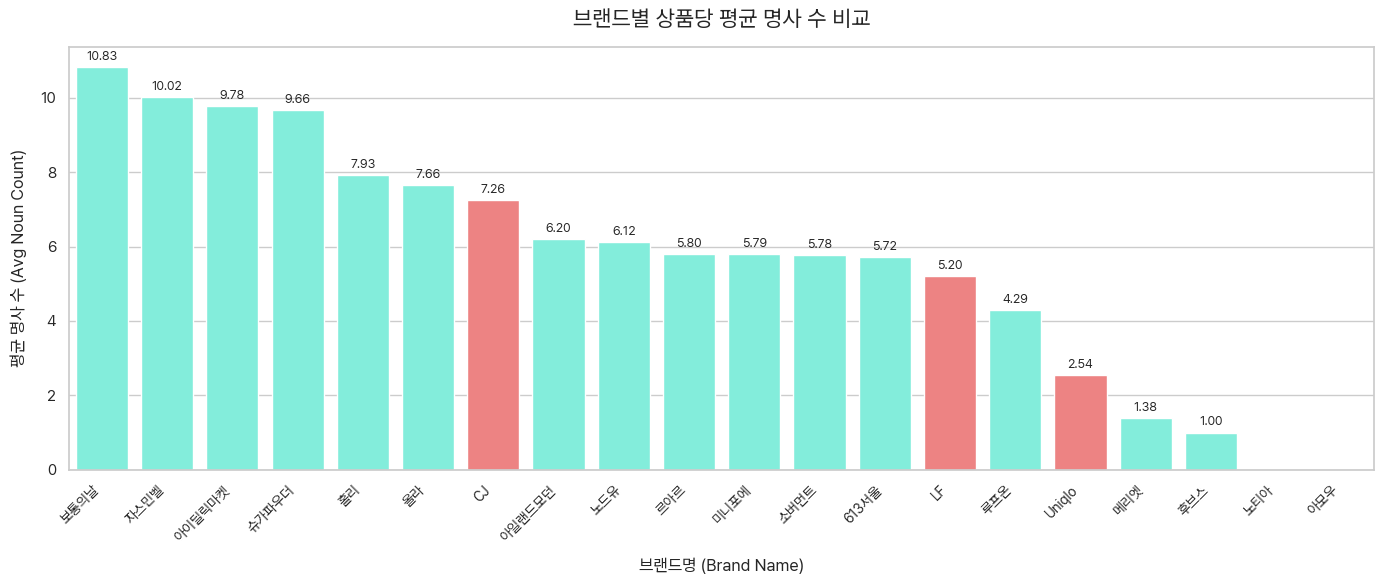

In [ ]:
import os
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

sns.set_theme(style="whitegrid")
font_path = r'C:\Users\hkssn\바탕 화면\multicam\project_db\PretendardVariable.ttf'

if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)
    font_prop = fm.FontProperties(fname=font_path)
    font_name = font_prop.get_name()
    plt.rc('font', family=font_name)
else:
    plt.rc('font', family='Malgun Gothic')

plt.rcParams['axes.unicode_minus'] = False

df_sorted = df_brand_summary.sort_values(by='avg_noun_count', ascending=False).reset_index(drop=True)

major_brands = ['CJ', 'LF', 'Uniqlo']

color_map = {
    brand: '#FF7171' if brand in major_brands else '#71FFE7'
    for brand in df_sorted['brand_name']
}

fig, ax = plt.subplots(figsize=(14, 6))

sns.barplot(
    data=df_sorted, 
    x='brand_name', 
    y='avg_noun_count', 
    palette=color_map,
    ax=ax
)

plt.title('브랜드별 상품당 평균 명사 수 비교', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('브랜드명 (Brand Name)', fontsize=12, labelpad=10)
plt.ylabel('평균 명사 수 (Avg Noun Count)', fontsize=12, labelpad=10)

plt.xticks(rotation=45, ha='right', fontsize=10)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f'{height:.2f}',
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='bottom',
            fontsize=9, fontweight='bold',
            xytext=(0, 3), textcoords='offset points'
        )

plt.tight_layout()
plt.show()

C:\Users\hkssn\AppData\Local\Temp\ipykernel_21564\2622739269.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


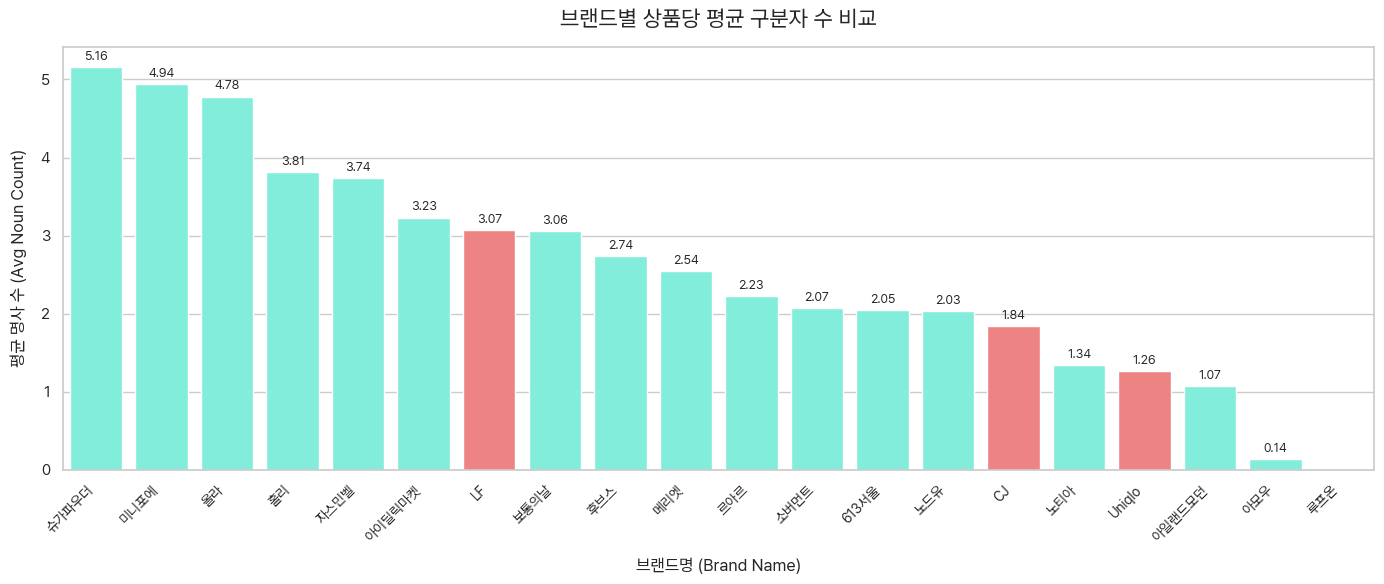

In [ ]:
import os
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

sns.set_theme(style="whitegrid")

font_path = r'C:\Users\hkssn\바탕 화면\multicam\project_db\PretendardVariable.ttf'

if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)
    font_prop = fm.FontProperties(fname=font_path)
    font_name = font_prop.get_name()
    plt.rc('font', family=font_name)
else:
    plt.rc('font', family='Malgun Gothic')

plt.rcParams['axes.unicode_minus'] = False

df_sorted = df_brand_summary.sort_values(by='avg_delimiter_count', ascending=False).reset_index(drop=True)
major_brands = ['CJ', 'LF', 'Uniqlo']
color_map = {
    brand: '#FF7171' if brand in major_brands else '#71FFE7'
    for brand in df_sorted['brand_name']
}

fig, ax = plt.subplots(figsize=(14, 6))

sns.barplot(
    data=df_sorted, 
    x='brand_name', 
    y='avg_delimiter_count', 
    palette=color_map,
    ax=ax
)


plt.title('브랜드별 상품당 평균 구분자 수 비교', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('브랜드명 (Brand Name)', fontsize=12, labelpad=10)
plt.ylabel('평균 명사 수 (Avg Noun Count)', fontsize=12, labelpad=10)

plt.xticks(rotation=45, ha='right', fontsize=10)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f'{height:.2f}',
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='bottom',
            fontsize=9, fontweight='bold',
            xytext=(0, 3), textcoords='offset points'
        )

plt.tight_layout()
plt.show()

C:\Users\hkssn\AppData\Local\Temp\ipykernel_21564\3531144243.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\hkssn\AppData\Local\Temp\ipykernel_21564\3531144243.py:86: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


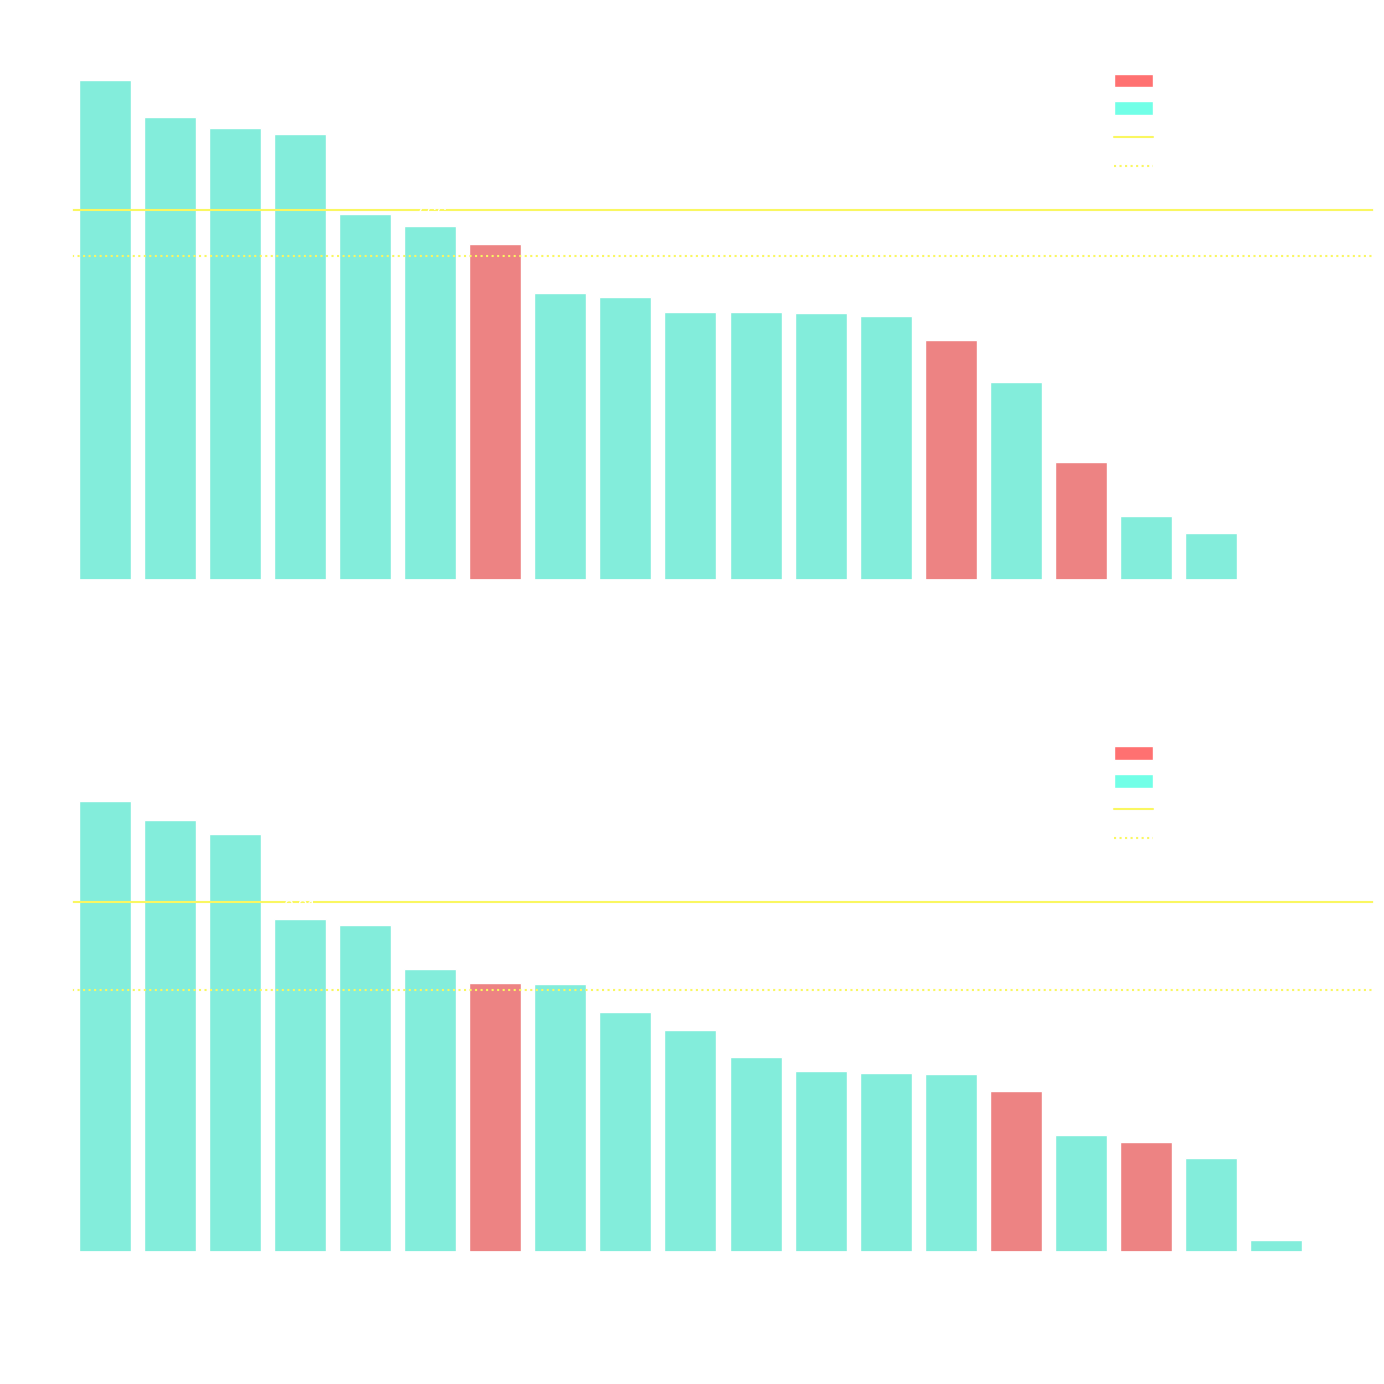

In [ ]:
import os
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from matplotlib.patches import Patch

sns.set_theme(style="whitegrid")
font_path = r'C:\Users\hkssn\바탕 화면\multicam\project_db\PretendardVariable.ttf'

if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)
    font_prop = fm.FontProperties(fname=font_path)
    font_name = font_prop.get_name()
    plt.rc('font', family=font_name)
else:
    plt.rc('font', family='Malgun Gothic')

plt.rcParams['axes.unicode_minus'] = False

major_brands = ['CJ', 'LF', 'Uniqlo']

fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(14, 14))

# ----------------------------------------------------
# [Top Graph] 1. 평균 명사 수 비교
# ----------------------------------------------------
df_noun_sorted = df_brand_summary.sort_values(by='avg_noun_count', ascending=False).reset_index(drop=True)
color_map_noun = {brand: '#FF7171' if brand in major_brands else '#71FFE7' for brand in df_noun_sorted['brand_name']}

sns.barplot(
    data=df_noun_sorted, 
    x='brand_name', 
    y='avg_noun_count', 
    palette=color_map_noun,
    ax=axes[0]
)

axes[0].set_title('브랜드별 상품당 평균 명사 수 비교', fontsize=28, fontweight='bold', pad=12, color='white')
axes[0].set_xlabel('')
axes[0].set_ylabel('평균 명사 수', fontsize=20, color='white')

# 상단 Threshold 기준선
axes[0].axhline(y=8.0, color='#FAF761', linestyle='-', linewidth=1.5)
axes[0].axhline(y=7.0, color='#FAF761', linestyle=':', linewidth=1.5)

# 상단 막대 위 수치
for p in axes[0].patches:
    height = p.get_height()
    if height > 0:
        axes[0].annotate(
            f'{height:.2f}',
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='bottom',
            fontsize=12, fontweight='bold',
            color='white',
            xytext=(0, 3), textcoords='offset points'
        )

# 상단 그래프 전용 범례
legend_elements_top = [
    Patch(facecolor='#FF7171', label='대기업 (Uniqlo, CJ, LF)'),
    Patch(facecolor='#71FFE7', label='소상공인 브랜드'),
    plt.Line2D([0], [0], color='#FAF761', linestyle='-', linewidth=1.5, label='Threshold (8개)'),
    plt.Line2D([0], [0], color='#FAF761', linestyle=':', linewidth=1.5, label='Threshold (7개)')
]

axes[0].legend(
    handles=legend_elements_top, 
    loc='upper right', 
    fontsize=14, 
    frameon=False, 
    labelcolor='#FFFFFF'
)

# ----------------------------------------------------
# [Bottom Graph] 2. 평균 구분자 수 비교
# ----------------------------------------------------
df_delim_sorted = df_brand_summary.sort_values(by='avg_delimiter_count', ascending=False).reset_index(drop=True)
color_map_delim = {brand: '#FF7171' if brand in major_brands else '#71FFE7' for brand in df_delim_sorted['brand_name']}

sns.barplot(
    data=df_delim_sorted, 
    x='brand_name', 
    y='avg_delimiter_count', 
    palette=color_map_delim,
    ax=axes[1]
)

axes[1].set_title('브랜드별 상품당 평균 구분자 수 비교', fontsize=28, fontweight='bold', pad=12, color='white')
axes[1].set_xlabel('브랜드명', fontsize=20, labelpad=8, color='white')
axes[1].set_ylabel('평균 구분자 수', fontsize=20, color='white')
axes[1].set_ylim(0, 6)

# 하단 Threshold 기준선
axes[1].axhline(y=4.0, color='#FAF761', linestyle='-', linewidth=1.5)
axes[1].axhline(y=3.0, color='#FAF761', linestyle=':', linewidth=1.5)

# 하단 막대 위 수치
for p in axes[1].patches:
    height = p.get_height()
    if height > 0:
        axes[1].annotate(
            f'{height:.2f}',
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='bottom',
            fontsize=12, fontweight='bold',
            color='white',
            xytext=(0, 3), textcoords='offset points'
        )

# 하단 그래프 전용 범례
legend_elements_bottom = [
    Patch(facecolor='#FF7171', label='대기업 (Uniqlo, CJ, LF)'),
    Patch(facecolor='#71FFE7', label='소상공인 브랜드'),
    plt.Line2D([0], [0], color='#FAF761', linestyle='-', linewidth=1.5, label='Threshold (4개)'),
    plt.Line2D([0], [0], color='#FAF761', linestyle=':', linewidth=1.5, label='Threshold (3개)')
]

axes[1].legend(
    handles=legend_elements_bottom, 
    loc='upper right', 
    fontsize=14, 
    frameon=False, 
    labelcolor='#FFFFFF'
)

# ----------------------------------------------------
# [전체 서브플롯 공통 텍스트/축/그리드 하얀색 처리 및 배경 투명화]
# ----------------------------------------------------
fig.patch.set_alpha(0.0) 

for ax in axes:
    ax.patch.set_alpha(0.0)
    
    ax.tick_params(axis='x', rotation=45, labelsize=12, colors='white')
    ax.tick_params(axis='y', labelsize=12, colors='white')
    
    for spine in ax.spines.values():
        spine.set_color('white')
        
    ax.grid(True, color='white', alpha=0.2)

plt.tight_layout()
plt.savefig('brand_comparison_dark_transparent.png', transparent=True, dpi=300, bbox_inches='tight')
plt.show()

C:\Users\hkssn\AppData\Local\Temp\ipykernel_21564\2973502472.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


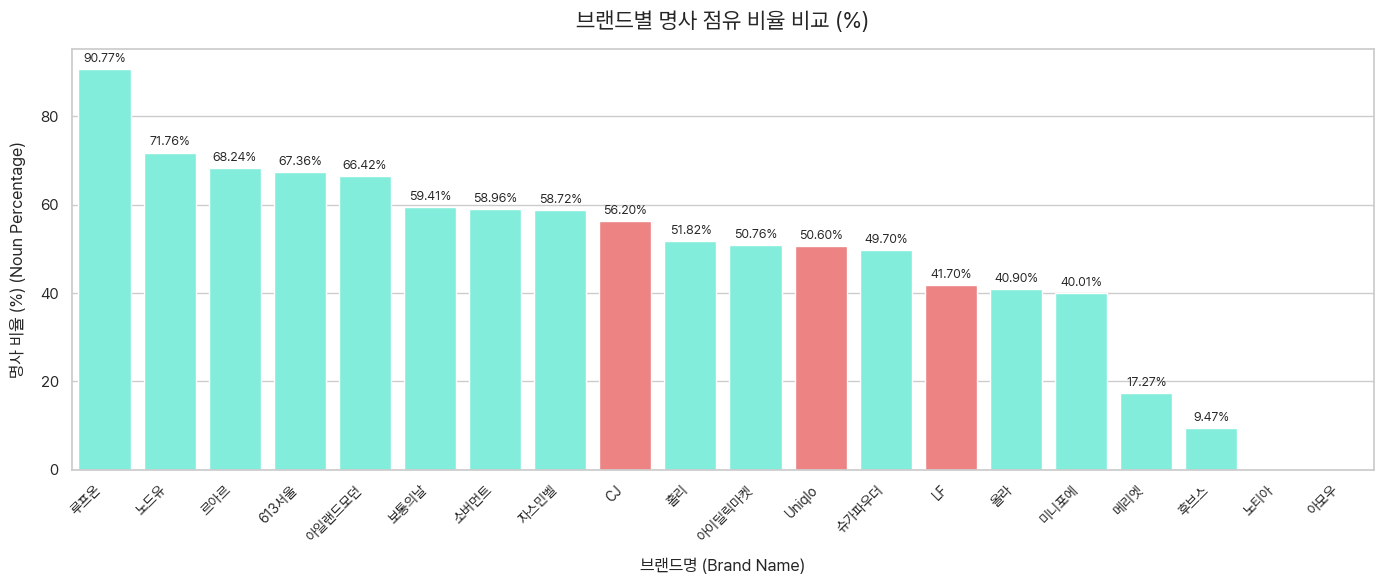

In [ ]:
import os
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

sns.set_theme(style="whitegrid")

font_path = r'C:\Users\hkssn\바탕 화면\multicam\project_db\PretendardVariable.ttf'

if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)
    font_prop = fm.FontProperties(fname=font_path)
    font_name = font_prop.get_name()
    plt.rc('font', family=font_name)
else:
    plt.rc('font', family='Malgun Gothic')

plt.rcParams['axes.unicode_minus'] = False

df_sorted = df_brand_summary.sort_values(by='noun_pct', ascending=False).reset_index(drop=True)

major_brands = ['CJ', 'LF', 'Uniqlo']

color_map = {
    brand: '#FF7171' if brand in major_brands else '#71FFE7'
    for brand in df_sorted['brand_name']
}

fig, ax = plt.subplots(figsize=(14, 6))

sns.barplot(
    data=df_sorted, 
    x='brand_name', 
    y='noun_pct', 
    palette=color_map,
    ax=ax
)

plt.title('브랜드별 명사 점유 비율 비교 (%)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('브랜드명 (Brand Name)', fontsize=12, labelpad=10)
plt.ylabel('명사 비율 (%) (Noun Percentage)', fontsize=12, labelpad=10)

plt.xticks(rotation=45, ha='right', fontsize=10)
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f'{height:.2f}%',
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='bottom',
            fontsize=9, fontweight='bold',
            xytext=(0, 3), textcoords='offset points'
        )

plt.tight_layout()
plt.show()

C:\Users\hkssn\AppData\Local\Temp\ipykernel_21564\4151843485.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


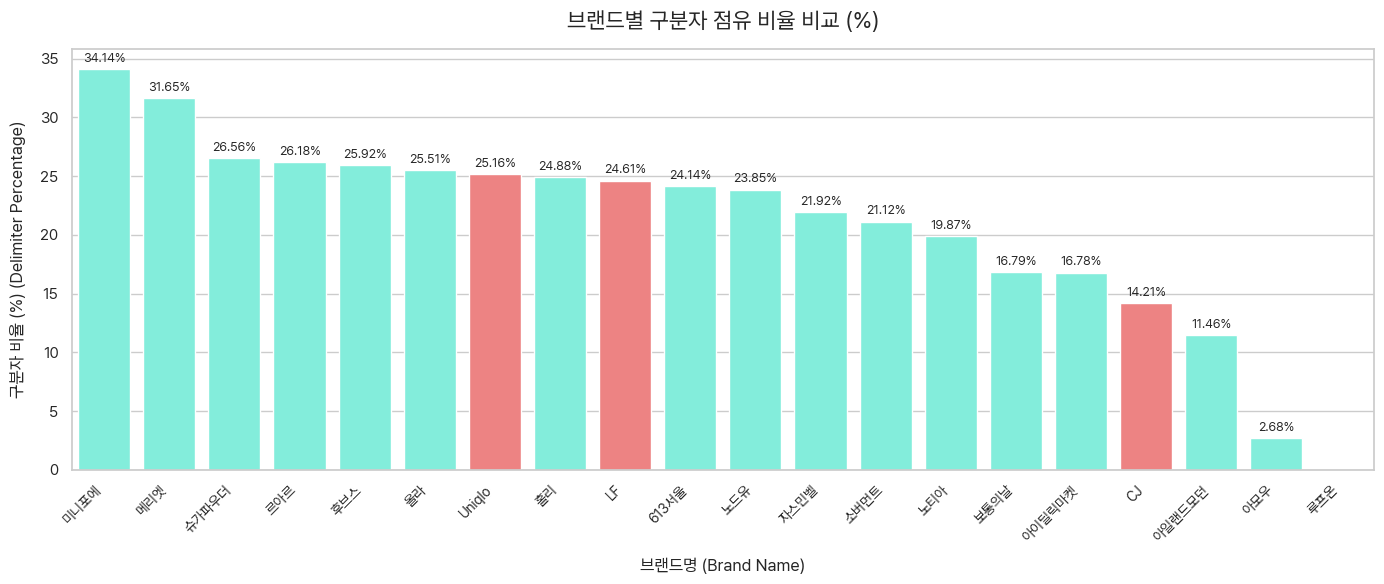

In [ ]:
import os
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

sns.set_theme(style="whitegrid")

font_path = r'C:\Users\hkssn\바탕 화면\multicam\project_db\PretendardVariable.ttf'

if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)
    font_prop = fm.FontProperties(fname=font_path)
    font_name = font_prop.get_name()
    plt.rc('font', family=font_name)
else:
    plt.rc('font', family='Malgun Gothic')

plt.rcParams['axes.unicode_minus'] = False

df_sorted = df_brand_summary.sort_values(by='delimiter_pct', ascending=False).reset_index(drop=True)

major_brands = ['CJ', 'LF', 'Uniqlo']

color_map = {
    brand: '#FF7171' if brand in major_brands else '#71FFE7'
    for brand in df_sorted['brand_name']
}

fig, ax = plt.subplots(figsize=(14, 6))

sns.barplot(
    data=df_sorted, 
    x='brand_name', 
    y='delimiter_pct', 
    palette=color_map,
    ax=ax
)

plt.title('브랜드별 구분자 점유 비율 비교 (%)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('브랜드명 (Brand Name)', fontsize=12, labelpad=10)
plt.ylabel('구분자 비율 (%) (Delimiter Percentage)', fontsize=12, labelpad=10)

plt.xticks(rotation=45, ha='right', fontsize=10)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f'{height:.2f}%',
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='bottom',
            fontsize=9, fontweight='bold',
            xytext=(0, 3), textcoords='offset points'
        )

plt.tight_layout()
plt.show()

C:\Users\hkssn\AppData\Local\Temp\ipykernel_21564\3564446961.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


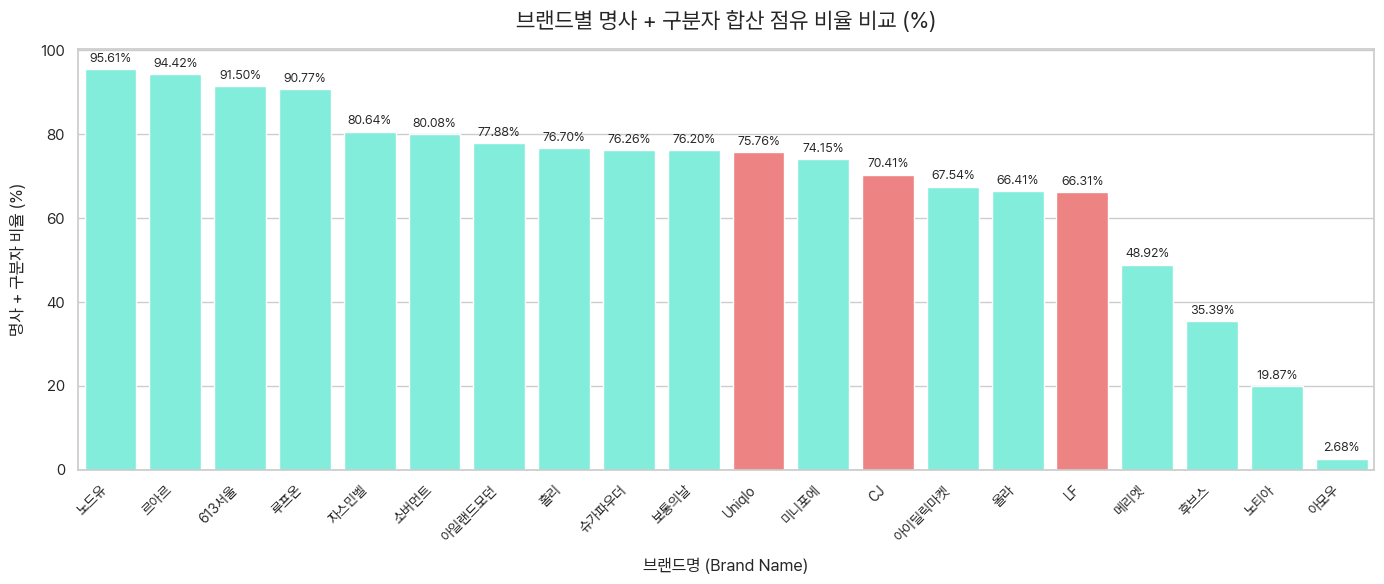

In [ ]:
import os
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

sns.set_theme(style="whitegrid")

font_path = r'C:\Users\hkssn\바탕 화면\multicam\project_db\PretendardVariable.ttf'

if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)
    font_prop = fm.FontProperties(fname=font_path)
    font_name = font_prop.get_name()
    plt.rc('font', family=font_name)
else:
    plt.rc('font', family='Malgun Gothic')

plt.rcParams['axes.unicode_minus'] = False

df_brand_summary['noun_plus_delimiter_pct'] = (
    df_brand_summary['noun_pct'] + df_brand_summary['delimiter_pct']
)

df_sorted = df_brand_summary.sort_values(
    by='noun_plus_delimiter_pct', ascending=False
).reset_index(drop=True)

major_brands = ['CJ', 'LF', 'Uniqlo']

color_map = {
    brand: '#FF7171' if brand in major_brands else '#71FFE7'
    for brand in df_sorted['brand_name']
}

fig, ax = plt.subplots(figsize=(14, 6))

sns.barplot(
    data=df_sorted, 
    x='brand_name', 
    y='noun_plus_delimiter_pct', 
    palette=color_map,
    ax=ax
)

plt.title('브랜드별 명사 + 구분자 합산 점유 비율 비교 (%)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('브랜드명 (Brand Name)', fontsize=12, labelpad=10)
plt.ylabel('명사 + 구분자 비율 (%)', fontsize=12, labelpad=10)

plt.xticks(rotation=45, ha='right', fontsize=10)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f'{height:.2f}%',
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='bottom',
            fontsize=9, fontweight='bold',
            xytext=(0, 3), textcoords='offset points'
        )

plt.tight_layout()
plt.show()

C:\Users\hkssn\AppData\Local\Temp\ipykernel_21564\508826235.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


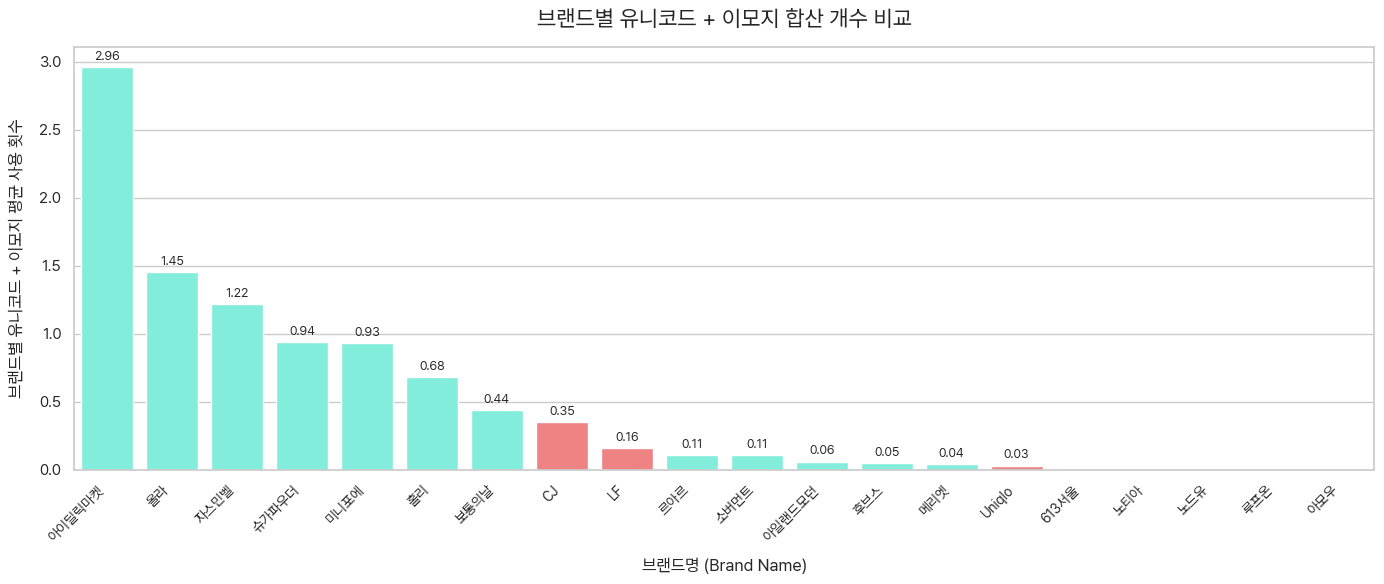

In [ ]:
import os
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

sns.set_theme(style="whitegrid")

font_path = r'C:\Users\hkssn\바탕 화면\multicam\project_db\PretendardVariable.ttf'

if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)
    font_prop = fm.FontProperties(fname=font_path)
    font_name = font_prop.get_name()
    plt.rc('font', family=font_name)
else:
    plt.rc('font', family='Malgun Gothic')

plt.rcParams['axes.unicode_minus'] = False

df_brand_summary['unicode_plus_emoji'] = (
    df_brand_summary['avg_unicode_count'] + df_brand_summary['avg_emoji_count']
)

df_sorted = df_brand_summary.sort_values(
    by='unicode_plus_emoji', ascending=False
).reset_index(drop=True)

major_brands = ['CJ', 'LF', 'Uniqlo']

color_map = {
    brand: '#FF7171' if brand in major_brands else '#71FFE7'
    for brand in df_sorted['brand_name']
}

fig, ax = plt.subplots(figsize=(14, 6))

sns.barplot(
    data=df_sorted, 
    x='brand_name', 
    y='unicode_plus_emoji', 
    palette=color_map,
    ax=ax
)

plt.title('브랜드별 유니코드 + 이모지 합산 개수 비교', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('브랜드명 (Brand Name)', fontsize=12, labelpad=10)
plt.ylabel('브랜드별 유니코드 + 이모지 평균 사용 횟수', fontsize=12, labelpad=10)

plt.xticks(rotation=45, ha='right', fontsize=10)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            round(height, 2),
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='bottom',
            fontsize=9, fontweight='bold',
            xytext=(0, 3), textcoords='offset points'
        )

plt.tight_layout()
plt.show()

C:\Users\hkssn\AppData\Local\Temp\ipykernel_21564\3596359893.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


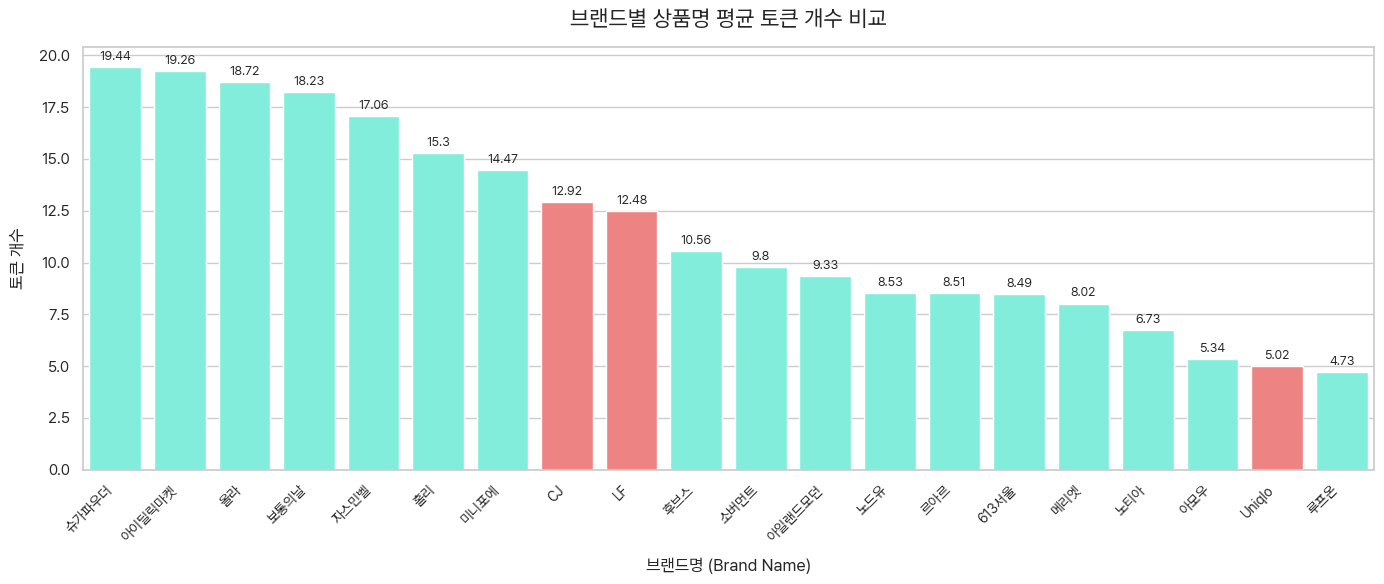

In [ ]:
import os
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

sns.set_theme(style="whitegrid")

font_path = r'C:\Users\hkssn\바탕 화면\multicam\project_db\PretendardVariable.ttf'

if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)
    font_prop = fm.FontProperties(fname=font_path)
    font_name = font_prop.get_name()
    plt.rc('font', family=font_name)
else:
    plt.rc('font', family='Malgun Gothic')

plt.rcParams['axes.unicode_minus'] = False

df_sorted = df_brand_summary.sort_values(
    by='avg_token_count', ascending=False
).reset_index(drop=True)

major_brands = ['CJ', 'LF', 'Uniqlo']

color_map = {
    brand: '#FF7171' if brand in major_brands else '#71FFE7'
    for brand in df_sorted['brand_name']
}

fig, ax = plt.subplots(figsize=(14, 6))

sns.barplot(
    data=df_sorted, 
    x='brand_name', 
    y='avg_token_count', 
    palette=color_map,
    ax=ax
)

plt.title('브랜드별 상품명 평균 토큰 개수 비교', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('브랜드명 (Brand Name)', fontsize=12, labelpad=10)
plt.ylabel('토큰 개수', fontsize=12, labelpad=10)

plt.xticks(rotation=45, ha='right', fontsize=10)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            height,
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='bottom',
            fontsize=9, fontweight='bold',
            xytext=(0, 3), textcoords='offset points'
        )

plt.tight_layout()
plt.show()

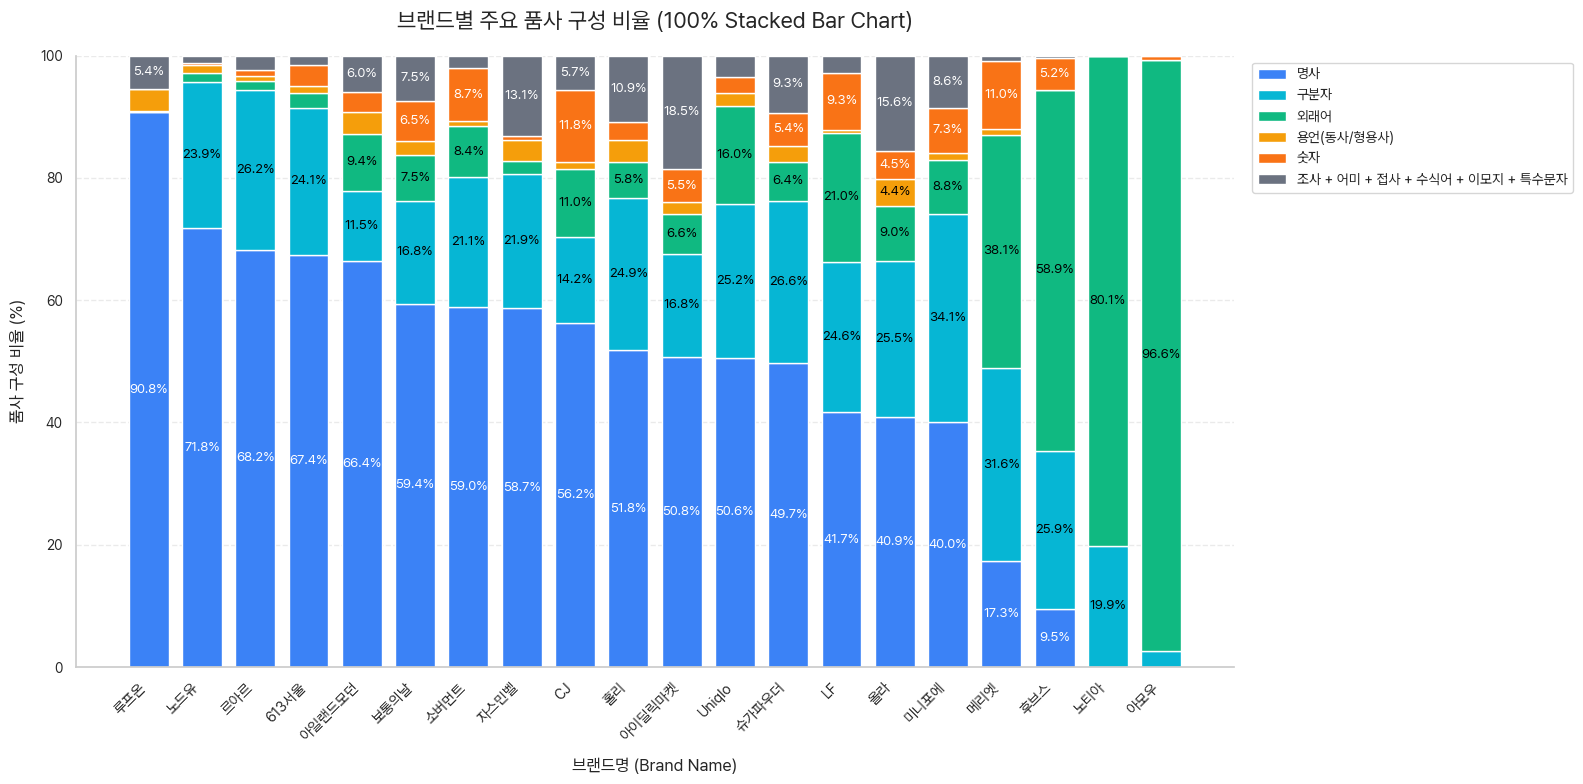

In [ ]:
import os
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import pandas as pd

font_path = r'C:\Users\hkssn\바탕 화면\multicam\project_db\PretendardVariable.ttf'

if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)
    font_prop = fm.FontProperties(fname=font_path)
    font_name = font_prop.get_name()
    plt.rc('font', family=font_name)
else:
    plt.rc('font', family='Malgun Gothic')

plt.rcParams['axes.unicode_minus'] = False

df_chart = df_brand_summary.copy()

main_cols = ['noun_pct', 'delimiter_pct', 'foreign_pct', 'verb_pct', 'number_pct']
minor_cols = [col for col in df_chart.columns if col.endswith('_pct') and col not in main_cols and col != 'etc_combined_pct']

df_chart['etc_combined_pct'] = df_chart[minor_cols].sum(axis=1)
df_chart['etc_combined_pct'] += (100.0 - (df_chart[main_cols].sum(axis=1) + df_chart['etc_combined_pct']))

pct_cols = ['noun_pct', 'delimiter_pct', 'foreign_pct', 'verb_pct', 'number_pct', 'etc_combined_pct']

col_labels = {
    'noun_pct': '명사',
    'delimiter_pct': '구분자',
    'foreign_pct': '외래어',
    'verb_pct': '용언(동사/형용사)',
    'number_pct': '숫자',
    'etc_combined_pct': '조사 + 어미 + 접사 + 수식어 + 이모지 + 특수문자'
}

df_chart = df_chart.sort_values(by='noun_pct', ascending=False).reset_index(drop=True)
brands = df_chart['brand_name'].tolist()

fig, ax = plt.subplots(figsize=(16, 8))

bottom_heights = [0.0] * len(df_chart)

# 색상 팔레트 및 배경별 텍스트 색상 (외곽선 없이 가독성이 확보되는 색상 조합)
colors = ['#3B82F6', '#06B6D4', '#10B981', '#F59E0B', '#F97316', '#6B7280']
text_colors = ['#FFFFFF', '#000000', '#000000', '#000000', '#FFFFFF', '#FFFFFF']

for idx, col in enumerate(pct_cols):
    values = df_chart[col].tolist()
    bars = ax.bar(
        brands, 
        values, 
        bottom=bottom_heights, 
        label=col_labels[col], 
        color=colors[idx],
        width=0.75,
        edgecolor='white',
        linewidth=1.0
    )
    
    for i, (bar, val) in enumerate(zip(bars, values)):
        if val >= 4.0:
            y_pos = bottom_heights[i] + val / 2
            
            ax.text(
                bar.get_x() + bar.get_width() / 2, 
                y_pos, 
                f'{val:.1f}%', 
                ha='center', va='center', 
                color=text_colors[idx], 
                fontweight='bold', 
                fontsize=9.5
            )
            
    bottom_heights = [b + v for b, v in zip(bottom_heights, values)]

plt.title('브랜드별 주요 품사 구성 비율 (100% Stacked Bar Chart)', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('브랜드명 (Brand Name)', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('품사 구성 비율 (%)', fontsize=12, fontweight='bold', labelpad=10)
plt.ylim(0, 100)

plt.xticks(rotation=45, ha='right', fontsize=10.5, fontweight='bold')
plt.yticks(fontsize=10)
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', frameon=True, fontsize=10)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

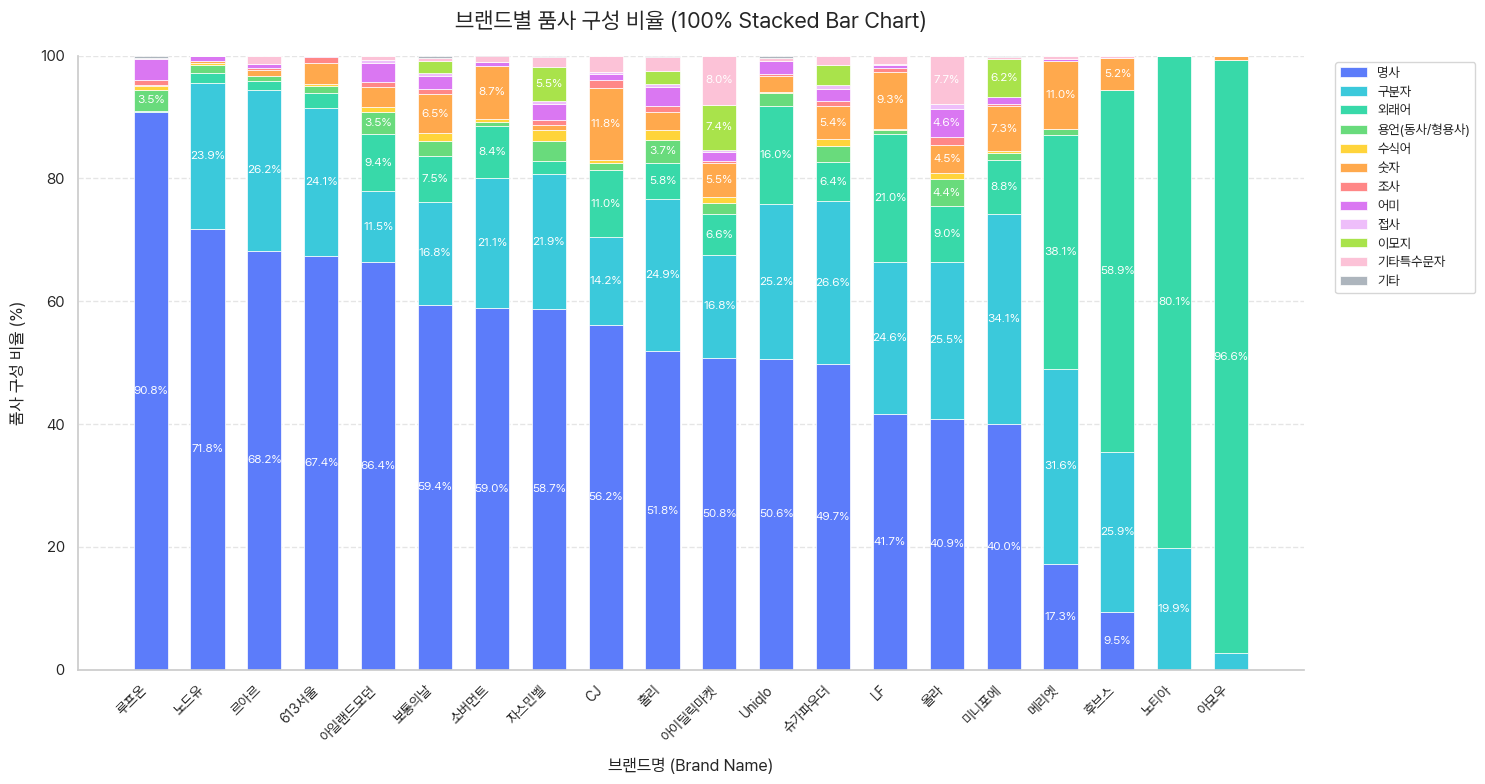

In [ ]:
import os
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import pandas as pd

font_path = r'C:\Users\hkssn\바탕 화면\multicam\project_db\PretendardVariable.ttf'

if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)
    font_prop = fm.FontProperties(fname=font_path)
    font_name = font_prop.get_name()
    plt.rc('font', family=font_name)
else:
    plt.rc('font', family='Malgun Gothic')

plt.rcParams['axes.unicode_minus'] = False

pct_cols = [
    'noun_pct', 'delimiter_pct', 'foreign_pct', 'verb_pct', 
    'modifier_pct', 'number_pct', 'josa_pct', 'eomi_pct', 
    'affix_pct', 'emoji_pct', 'unicode_pct', 'etc_pct'
]

col_labels = {
    'noun_pct': '명사',
    'delimiter_pct': '구분자',
    'foreign_pct': '외래어',
    'verb_pct': '용언(동사/형용사)',
    'modifier_pct': '수식어',
    'number_pct': '숫자',
    'josa_pct': '조사',
    'eomi_pct': '어미',
    'affix_pct': '접사',
    'emoji_pct': '이모지',
    'unicode_pct': '기타특수문자',
    'etc_pct': '기타'
}

df_chart = df_brand_summary.copy()

existing_cols = [c for c in pct_cols if c in df_chart.columns]

df_chart['current_sum'] = df_chart[existing_cols].sum(axis=1)
if 'etc_pct' in df_chart.columns:
    df_chart['etc_pct'] += (100.0 - df_chart['current_sum'])
else:
    df_chart['etc_pct'] = (100.0 - df_chart['current_sum'])

df_chart = df_chart.sort_values(by='noun_pct', ascending=False).reset_index(drop=True)
brands = df_chart['brand_name'].tolist()

fig, ax = plt.subplots(figsize=(15, 8))

bottom_heights = [0.0] * len(df_chart)

colors = [
    '#5c7cfa', '#3bc9db', '#38d9a9', '#69db7c', '#ffd43b', 
    '#ffa94d', '#ff8787', '#da77f2', '#eebefa', '#a9e34b', '#fcc2d7', '#adb5bd'
]

for idx, col in enumerate(existing_cols):
    values = df_chart[col].tolist()
    bars = ax.bar(
        brands, 
        values, 
        bottom=bottom_heights, 
        label=col_labels.get(col, col), 
        color=colors[idx % len(colors)],
        width=0.6,
        edgecolor='white',
        linewidth=0.5
    )
    
    for i, (bar, val) in enumerate(zip(bars, values)):
        if val >= 3.5:
            y_pos = bottom_heights[i] + val / 2
            ax.text(
                bar.get_x() + bar.get_width() / 2, 
                y_pos, 
                f'{val:.1f}%', 
                ha='center', va='center', 
                color='white', fontweight='bold', fontsize=8.5
            )
            
    bottom_heights = [b + v for b, v in zip(bottom_heights, values)]

plt.title('브랜드별 품사 구성 비율 (100% Stacked Bar Chart)', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('브랜드명 (Brand Name)', fontsize=12, labelpad=10)
plt.ylabel('품사 구성 비율 (%)', fontsize=12, labelpad=10)
plt.ylim(0, 100)

plt.xticks(rotation=45, ha='right', fontsize=10)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True, fontsize=9.5)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

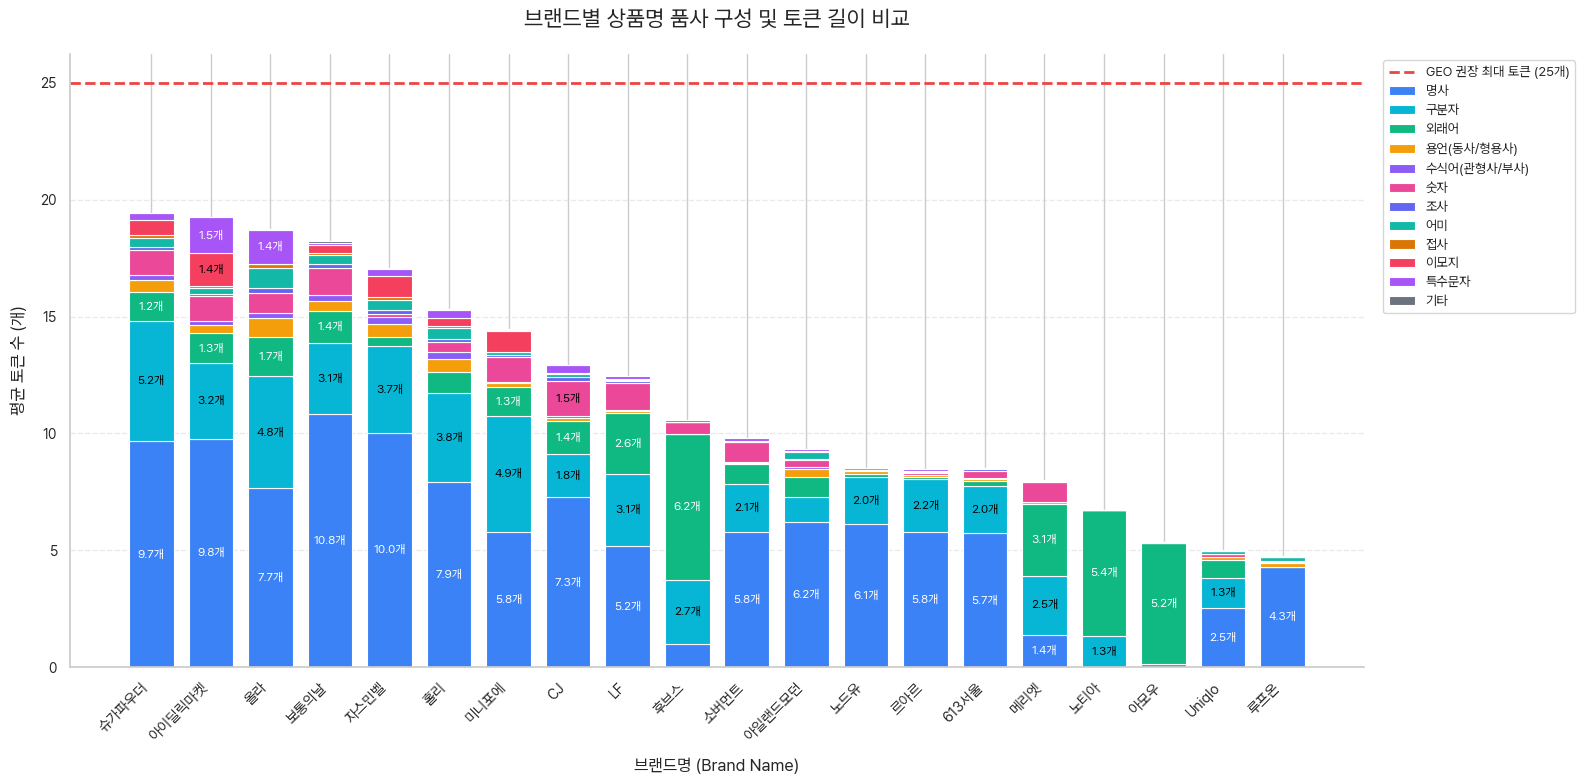

In [ ]:
import os
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

font_path = r'C:\Users\hkssn\바탕 화면\multicam\project_db\PretendardVariable.ttf'

if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)
    font_prop = fm.FontProperties(fname=font_path)
    font_name = font_prop.get_name()
    plt.rc('font', family=font_name)
else:
    plt.rc('font', family='Malgun Gothic')

plt.rcParams['axes.unicode_minus'] = False

df_chart = df_brand_summary.copy()

count_cols = [
    'avg_noun_count', 'avg_delimiter_count', 'avg_foreign_count', 'avg_verb_count',
    'avg_modifier_count', 'avg_number_count', 'avg_josa_count', 'avg_eomi_count',
    'avg_affix_count', 'avg_emoji_count', 'avg_unicode_count', 'avg_etc_count'
]

existing_cols = [c for c in count_cols if c in df_chart.columns]

col_labels = {
    'avg_noun_count': '명사',
    'avg_delimiter_count': '구분자',
    'avg_foreign_count': '외래어',
    'avg_verb_count': '용언(동사/형용사)',
    'avg_modifier_count': '수식어(관형사/부사)',
    'avg_number_count': '숫자',
    'avg_josa_count': '조사',
    'avg_eomi_count': '어미',
    'avg_affix_count': '접사',
    'avg_emoji_count': '이모지',
    'avg_unicode_count': '특수문자',
    'avg_etc_count': '기타'
}

df_chart = df_chart.sort_values(by='avg_token_count', ascending=False).reset_index(drop=True)
brands = df_chart['brand_name'].tolist()

fig, ax = plt.subplots(figsize=(16, 8))

bottom_heights = [0.0] * len(df_chart)

colors = [
    '#3B82F6', '#06B6D4', '#10B981', '#F59E0B', '#8B5CF6', 
    '#EC4899', '#6366F1', '#14B8A6', '#D97706', '#F43F5E', '#A855F7', '#6B7280'
]

for idx, col in enumerate(existing_cols):
    values = df_chart[col].tolist()
    label_str = col_labels.get(col, col)
    
    bars = ax.bar(
        brands, 
        values, 
        bottom=bottom_heights, 
        label=label_str, 
        color=colors[idx % len(colors)],
        width=0.75,
        edgecolor='white',
        linewidth=0.8
    )
    
    for i, (bar, val) in enumerate(zip(bars, values)):
        if val >= 1.2:
            y_pos = bottom_heights[i] + val / 2
            
            ax.text(
                bar.get_x() + bar.get_width() / 2, 
                y_pos, 
                f'{val:.1f}개', 
                ha='center', va='center', 
                color='#FFFFFF' if idx in [0, 2, 4, 6, 8, 10] else '#000000', 
                fontweight='bold', 
                fontsize=8.5
            )
            
    bottom_heights = [b + v for b, v in zip(bottom_heights, values)]

MAX_TOKEN_LIMIT = 25
ax.axhline(y=MAX_TOKEN_LIMIT, color='#EF4444', linestyle='--', linewidth=2, label=f'GEO 권장 최대 토큰 ({MAX_TOKEN_LIMIT}개)')

plt.title('브랜드별 상품명 품사 구성 및 토큰 길이 비교', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('브랜드명 (Brand Name)', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('평균 토큰 수 (개)', fontsize=12, fontweight='bold', labelpad=10)

plt.xticks(rotation=45, ha='right', fontsize=10.5, fontweight='bold')
plt.yticks(fontsize=10)
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', frameon=True, fontsize=9.5)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

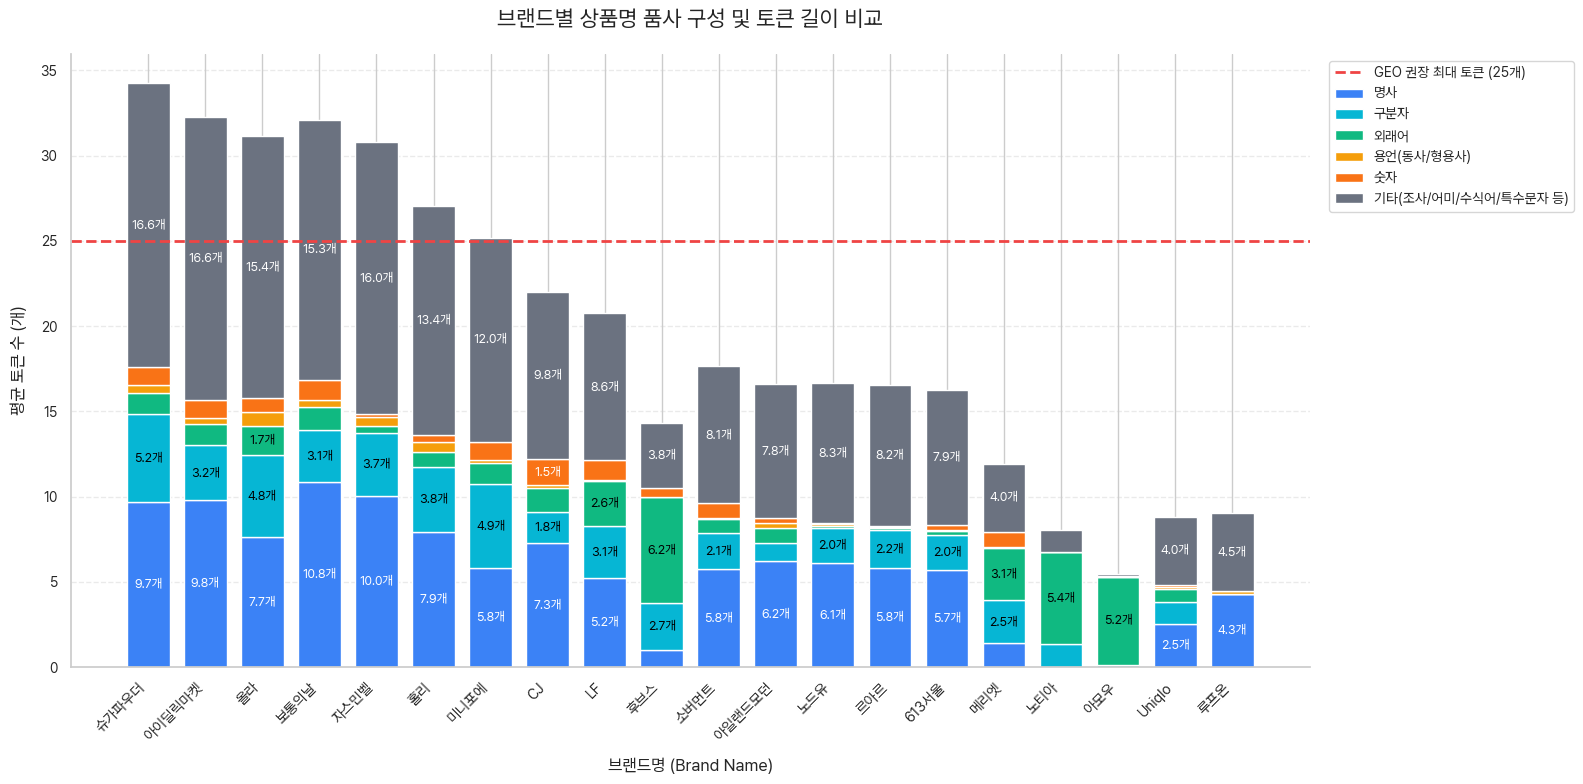

In [ ]:
import os
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import pandas as pd

font_path = r'C:\Users\hkssn\바탕 화면\multicam\project_db\PretendardVariable.ttf'

if os.path.exists(font_path):
  fm.fontManager.addfont(font_path)
  font_prop = fm.FontProperties(fname=font_path)
  font_name = font_prop.get_name()
  plt.rc('font', family=font_name)
else:
  plt.rc('font', family='Malgun Gothic')

plt.rcParams['axes.unicode_minus'] = False

df_chart = df_brand_summary.copy()
token_col = 'avg_token_count'

main_cols = [
    'noun_pct',
    'delimiter_pct',
    'foreign_pct',
    'verb_pct',
    'number_pct',
]
minor_cols = [
    col
    for col in df_chart.columns
    if col.endswith('_pct')
    and col not in main_cols
    and col != 'etc_combined_pct'
]

df_chart['etc_combined_pct'] = df_chart[minor_cols].sum(axis=1)
pct_cols = [
    'noun_pct',
    'delimiter_pct',
    'foreign_pct',
    'verb_pct',
    'number_pct',
    'etc_combined_pct',
]

for col in pct_cols:
  token_col_name = col.replace('_pct', '_token_cnt')
  df_chart[token_col_name] = (df_chart[col] / 100.0) * df_chart[token_col]

target_cols = [col.replace('_pct', '_token_cnt') for col in pct_cols]

col_labels = {
    'noun': '명사',
    'delimiter': '구분자',
    'foreign': '외래어',
    'verb': '용언(동사/형용사)',
    'number': '숫자',
    'etc_combined': '기타(조사/어미/수식어/특수문자 등)',
}

df_chart = df_chart.sort_values(by=token_col, ascending=False).reset_index(
    drop=True
)
brands = df_chart['brand_name'].tolist()

# 3. 그래프 생성
fig, ax = plt.subplots(figsize=(16, 8))

bottom_heights = [0.0] * len(df_chart)
colors = ['#3B82F6', '#06B6D4', '#10B981', '#F59E0B', '#F97316', '#6B7280']
text_colors = ['#FFFFFF', '#000000', '#000000', '#000000', '#FFFFFF', '#FFFFFF']

for idx, col in enumerate(target_cols):
  values = df_chart[col].tolist()

  key = col.replace('_token_cnt', '').replace('_pct', '')
  label_str = col_labels.get(key, key)

  bars = ax.bar(
      brands,
      values,
      bottom=bottom_heights,
      label=label_str,
      color=colors[idx],
      width=0.75,
      edgecolor='white',
      linewidth=1.0,
  )

  for i, (bar, val) in enumerate(zip(bars, values)):
    if val >= 1.5:  # 1.5개 이상만 표시
      y_pos = bottom_heights[i] + val / 2

      ax.text(
          bar.get_x() + bar.get_width() / 2,
          y_pos,
          f'{val:.1f}개',
          ha='center',
          va='center',
          color=text_colors[idx],
          fontweight='bold',
          fontsize=9.0,
      )

  bottom_heights = [b + v for b, v in zip(bottom_heights, values)]

MAX_TOKEN_LIMIT = 25
ax.axhline(
    y=MAX_TOKEN_LIMIT,
    color='#EF4444',
    linestyle='--',
    linewidth=2,
    label=f'GEO 권장 최대 토큰 ({MAX_TOKEN_LIMIT}개)',
)

plt.title(
    '브랜드별 상품명 품사 구성 및 토큰 길이 비교',
    fontsize=16,
    fontweight='bold',
    pad=20,
)
plt.xlabel('브랜드명 (Brand Name)', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel(
    '평균 토큰 수 (개)', fontsize=12, fontweight='bold', labelpad=10
)

plt.xticks(rotation=45, ha='right', fontsize=10.5, fontweight='bold')
plt.yticks(fontsize=10)
plt.legend(
    bbox_to_anchor=(1.01, 1), loc='upper left', frameon=True, fontsize=10
)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

KeyError: 'noun_ratio'

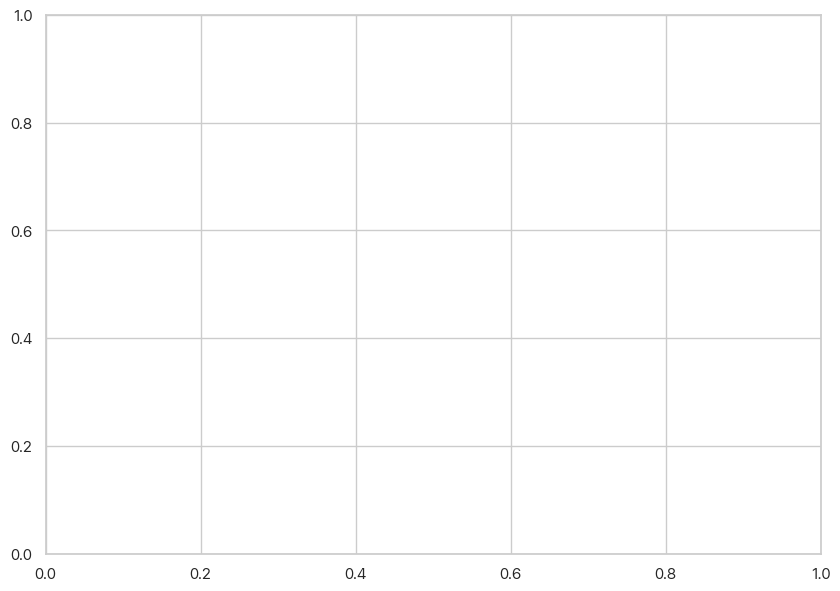

In [ ]:
fig, ax = plt.subplots(figsize=(10, 7))

for i, row in df_brand_summary.iterrows():
    # 고위험군 강조
    is_risk = (row['avg_noun_count'] >= 6.0) and (row['noun_ratio'] >= 0.75)
    color = '#E53E3E' if is_risk else '#3182CE'
    
    ax.scatter(row['avg_noun_count'], row['noun_ratio']*100, color=color, s=120, alpha=0.8, edgecolors='black', linewidth=0.5)
    
    ax.annotate(
        row['brand_name'], 
        (row['avg_noun_count'], row['noun_ratio']*100),
        xytext=(5, 5), textcoords='offset points',
        fontsize=9, fontweight='bold' if is_risk else 'normal',
        color='#C53030' if is_risk else '#2D3748'
    )

ax.axvline(x=6.0, color='#E53E3E', linestyle='--', linewidth=1.5) # 명사 6개 선
ax.axhline(y=75.0, color='#E53E3E', linestyle='--', linewidth=1.5) # 비율 75% 선

ax.axvspan(6.0, 12.0, ymin=75/110, ymax=1.0, color='#FFF5F5', alpha=0.7, zorder=0)
ax.text(6.2, 102, '★ 고위험 스터핑 영역', color='#E53E3E', fontweight='bold', fontsize=11)

ax.set_xlim(0, 12)
ax.set_ylim(0, 110)
ax.set_xlabel('평균 명사 개수 (개)', fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylabel('명사 비율 (%)', fontsize=11, fontweight='bold', labelpad=10)
plt.title('명사 개수 vs 명사 비율 사분면 매트릭스 (스터핑 진단)', fontsize=14, fontweight='bold', pad=15)

plt.tight_layout()
plt.show()

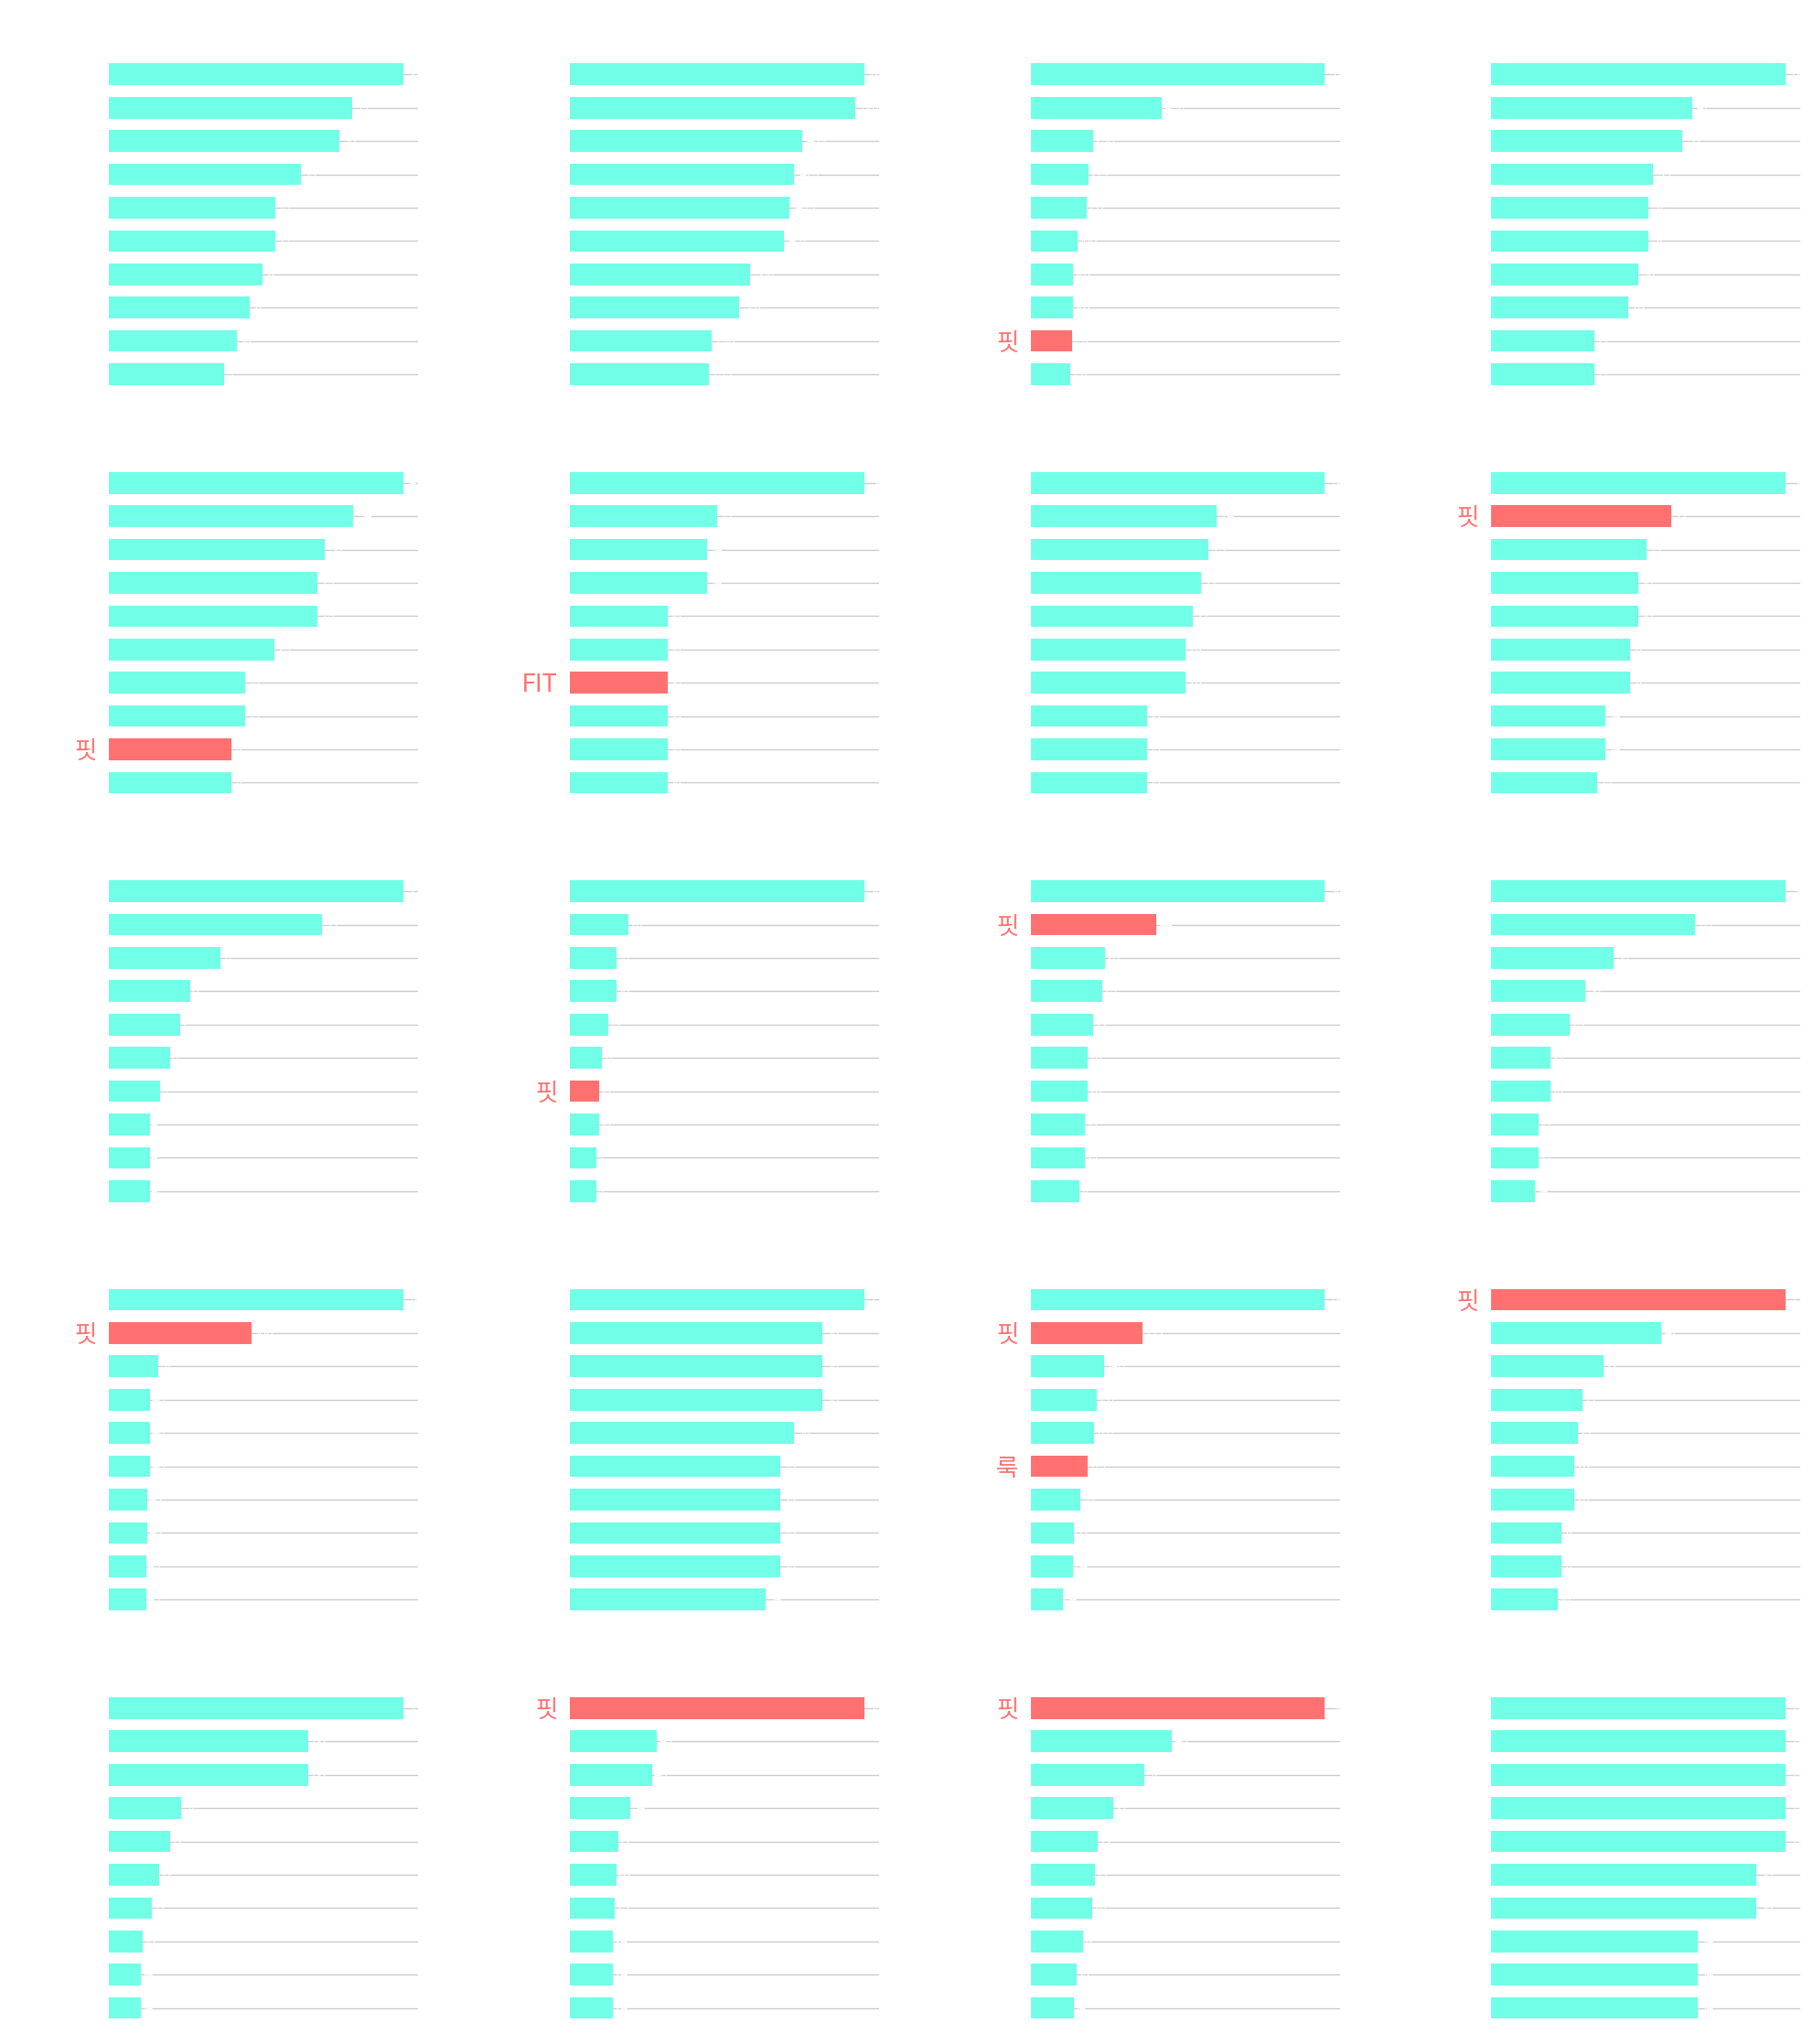

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

target_keywords = {'핏', '룩', '템', 'LOOK', 'FIT'}

melted_rows = []
for _, row in df_brand_top_tokens.iterrows():
  for i in range(1, 11):
    w = row[f'top_{i}_word']
    c = row[f'top_{i}_count']
    if w and c > 0:
      melted_rows.append(
          {'brand_name': row['brand_name'], 'word': w, 'count': c}
      )

df_top_melt = pd.DataFrame(melted_rows)

brands = df_top_melt['brand_name'].unique()
cols = 4
rows = (len(brands) + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(20, 4.5 * rows))
fig.patch.set_alpha(0.0)
axes = axes.flatten()

for idx, brand in enumerate(brands):
  ax = axes[idx]
  ax.patch.set_alpha(0.0)

  brand_data = df_top_melt[df_top_melt['brand_name'] == brand].sort_values(
      by='count', ascending=True
  )

  bar_colors = [
      '#FF7171' if str(word).upper() in target_keywords else '#71FFE7'
      for word in brand_data['word']
  ]

  bars = ax.barh(
      brand_data['word'],
      brand_data['count'],
      color=bar_colors,
      edgecolor='none',
      height=0.65,
  )

  ax.set_title(brand, fontsize=28, fontweight='bold', color='#FFFFFF', pad=10)

  for spine in ax.spines.values():
    spine.set_visible(False)

  ax.xaxis.set_visible(False)
  ax.tick_params(axis='y', colors='#FFFFFF', labelsize=20)
  for tick_label in ax.get_yticklabels():
    text = tick_label.get_text()
    if str(text).upper() in target_keywords:
      tick_label.set_color('#FF7171')
      tick_label.set_fontweight('bold')
    else:
      tick_label.set_color('#FFFFFF')

  for bar in bars:
    width = bar.get_width()
    ax.text(
        width + (width * 0.02),
        bar.get_y() + bar.get_height() / 2,
        f'{int(width)}',
        va='center',
        ha='left',
        fontsize=9,
        color='#FFFFFF',
    )

for j in range(idx + 1, len(axes)):
  fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

C:\Users\hkssn\AppData\Local\Temp\ipykernel_22260\4287997792.py:73: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


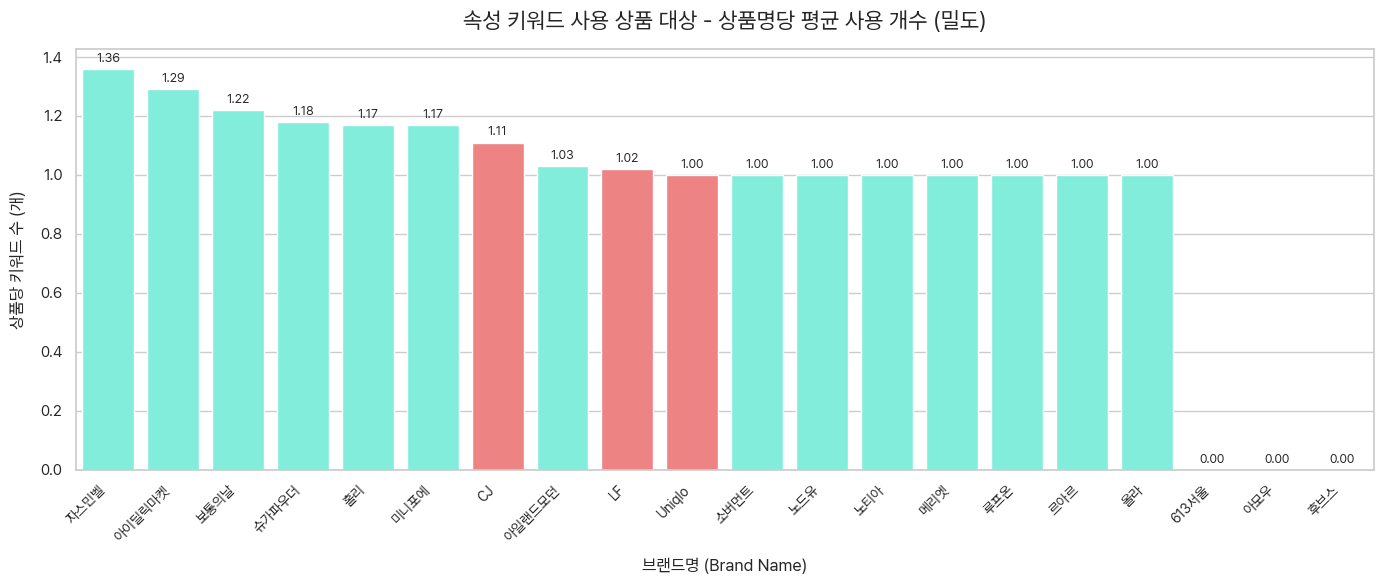

In [ ]:
import os
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

target_suffixes = ('핏', '룩', '템', 'LOOK', 'FIT', 'ITEM')
target_exact = {'핏', '룩', '템', 'LOOK', 'FIT', 'ITEM'}

attr_dense_rows = []

for brand, group in df.groupby('brand_name'):
  product_counts = []

  for product_name in group['product_name'].dropna():
    tokens = kiwi.tokenize(product_name)
    count_in_product = 0

    for token in tokens:
      form_upper = token.form.upper()
      if form_upper.endswith(target_suffixes) or form_upper in target_exact:
        count_in_product += 1

    if count_in_product > 0:
      product_counts.append(count_in_product)

  if len(product_counts) > 0:
    avg_density = round(sum(product_counts) / len(product_counts), 2)
  else:
    avg_density = 0.0

  attr_dense_rows.append(
      {
          'brand_name': brand,
          'avg_density': avg_density,
          'used_product_cnt': len(product_counts),
      }
  )

df_attr_dense = pd.DataFrame(attr_dense_rows)

# ==========================================
# 시각화 (기존 스타일 100% 유지)
# ==========================================
sns.set_theme(style='whitegrid')

font_path = (
    r'C:\Users\hkssn\바탕 화면\multicam\project_db\PretendardVariable.ttf'
)
if os.path.exists(font_path):
  fm.fontManager.addfont(font_path)
  font_prop = fm.FontProperties(fname=font_path)
  plt.rc('font', family=font_prop.get_name())
else:
  plt.rc('font', family='Malgun Gothic')

plt.rcParams['axes.unicode_minus'] = False

df_sorted = df_attr_dense.sort_values(
    by='avg_density', ascending=False
).reset_index(drop=True)

major_brands = ['CJ', 'LF', 'Uniqlo']
color_map = {
    brand: '#FF7171' if brand in major_brands else '#71FFE7'
    for brand in df_sorted['brand_name']
}

fig, ax = plt.subplots(figsize=(14, 6))

sns.barplot(
    data=df_sorted, x='brand_name', y='avg_density', palette=color_map, ax=ax
)

plt.title(
    '속성 키워드 사용 상품 대상 - 상품명당 평균 사용 개수 (밀도)',
    fontsize=16,
    fontweight='bold',
    pad=15,
)
plt.xlabel('브랜드명 (Brand Name)', fontsize=12, labelpad=10)
plt.ylabel('상품당 키워드 수 (개)', fontsize=12, labelpad=10)
plt.xticks(rotation=45, ha='right', fontsize=10)

for p in ax.patches:
  height = p.get_height()
  if height >= 0:
    ax.annotate(
        f'{height:.2f}',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold',
        xytext=(0, 3),
        textcoords='offset points',
    )

plt.tight_layout()
plt.show()

##### 2차

In [7]:
from sqlalchemy import text

query = text("""
    SELECT 
        r.page_id,
        r.product_name,
        d.keyword_stuffing_score
    FROM diagnosis_table d
    JOIN raw_data_table r ON d.page_id = r.page_id
    WHERE d.is_corrected = 0 and d.model_ver = '3.2.3'  -- 필요시: 교정 전(0) 또는 교정 후(1) 조건 추가
""")

with engine.connect() as conn:
    results = conn.execute(query).mappings().fetchall()

df = pd.DataFrame(results)

In [8]:
df.head()

,page_id,product_name,keyword_stuffing_score
0,1,남성 쿨 원턱 와이드 트레이닝팬츠 PHG2PT1759,0.90
1,2,트레이닝 반바지 249PT262,1.00
2,3,남성 여성 커플 냉장고바지 쿨팬츠 8부 9부 아이스바지,0.65
3,4,캘빈클라인 에센셜 셋업 3종 세트 남여공용,0.75
4,5,7부 바지 스판 밴딩 냉장고 쿨링 아이스 냉감 칠부 츄리닝 트레이닝 팬츠,0.75


In [6]:
df.loc[0, 'product_name']

'남성 쿨 원턱 와이드 트레이닝팬츠 PHG2PT1759'

In [10]:
from kiwipiepy import Kiwi

# Kiwi 객체 생성
kiwi = Kiwi()

# 토큰 개수를 반환하는 함수 정의 (None이나 빈 문자열 방어 코드 포함)
def get_token_length(text):
    if not text or not isinstance(text, str):
        return 0
    return len(kiwi.tokenize(text))

# apply를 활용하여 빠르게 토큰 길이 컬럼 추가
df['pn_length'] = df['product_name'].apply(get_token_length)

df.head()

,page_id,product_name,keyword_stuffing_score,pn_length
0,1,남성 쿨 원턱 와이드 트레이닝팬츠 PHG2PT1759,0.90,11
1,2,트레이닝 반바지 249PT262,1.00,5
2,3,남성 여성 커플 냉장고바지 쿨팬츠 8부 9부 아이스바지,0.65,14
3,4,캘빈클라인 에센셜 셋업 3종 세트 남여공용,0.75,10
4,5,7부 바지 스판 밴딩 냉장고 쿨링 아이스 냉감 칠부 츄리닝 트레이닝 팬츠,0.75,15


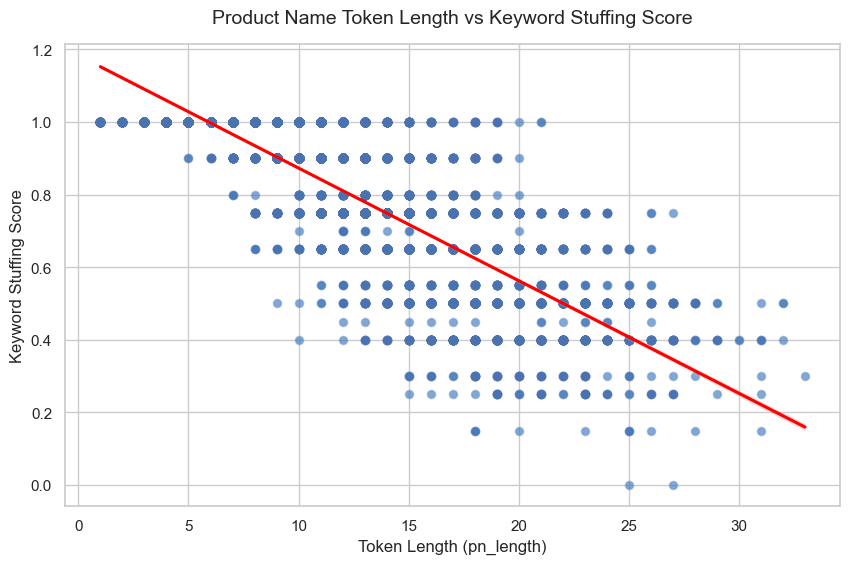

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rc('font', family='NanumGothic')
plt.rc('axes', unicode_minus=False)

plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

sns.scatterplot(
    data=df, 
    x='pn_length', 
    y='keyword_stuffing_score',
    alpha=0.5,
    color='#3182ce'
)


sns.regplot(data=df, x='pn_length', y='keyword_stuffing_score', scatter_kws={'alpha': 0.3}, line_kws={'color': 'red'})

plt.title('Product Name Token Length vs Keyword Stuffing Score', fontsize=14, pad=15)
plt.xlabel('Token Length (pn_length)', fontsize=12)
plt.ylabel('Keyword Stuffing Score', fontsize=12)

plt.show()

In [ ]:
import scipy.stats as stats

pearson_coef, p_val_pearson = stats.pearsonr(df['pn_length'], df['keyword_stuffing_score'])
spearman_coef, p_val_spearman = stats.spearmanr(df['pn_length'], df['keyword_stuffing_score'])

print(f"📊 [Pearson] 상관계수: {pearson_coef:.4f} (p-value: {p_val_pearson:.4e})")
print(f"📊 [Spearman] 상관계수: {spearman_coef:.4f} (p-value: {p_val_spearman:.4e})")

📊 [Pearson] 상관계수: -0.8206 (p-value: 0.0000e+00)
📊 [Spearman] 상관계수: -0.8474 (p-value: 0.0000e+00)


#### 교정 전후 차이 검정 (진단 모델)

In [ ]:
import pandas as pd
import numpy as np
from scipy import stats
from sqlalchemy import text

query = text("""
    SELECT 
        d.page_id,
        MAX(CASE WHEN d.is_corrected = 0 THEN d.geo_score END) AS score_before,
        MAX(CASE WHEN d.is_corrected = 1 THEN d.geo_score END) AS score_after
    FROM diagnosis_table d
    INNER JOIN (
        SELECT DISTINCT page_id 
        FROM diagnosis_table 
        WHERE is_corrected = 1
        and model_ver = '3.2.3'
    ) c ON d.page_id = c.page_id
    GROUP BY d.page_id
    HAVING score_before IS NOT NULL AND score_after IS NOT NULL;
""")

with engine.connect() as conn:
    df = pd.read_sql(query, conn)

df['score_diff'] = df['score_after'] - df['score_before']

mean_before = df['score_before'].mean()
mean_after = df['score_after'].mean()
mean_diff = df['score_diff'].mean()

print("=== [기초 통계량] ===")
print(f"총 샘플 수: {len(df):,}개")
print(f"교정 전 평균 GEO Score: {mean_before:.2f}")
print(f"교정 후 평균 GEO Score: {mean_after:.2f}")
print(f"평균 점수 변화량: {mean_diff:+.2f}\n")

# 3. 정규성 검정 (Shapiro-Wilk Test - 샘플 수가 많을 경우 Kolmogorov-Smirnov 사용)
# 표본 수 5000개 초과 시 Shapiro-Wilk 한계 고려
if len(df) <= 5000:
    normality_stat, normality_p = stats.shapiro(df['score_diff'])
else:
    normality_stat, normality_p = stats.kstest(df['score_diff'], 'norm')

print("=== [차이값의 정규성 검정] ===")
print(f"Statistic: {normality_stat:.4f}, p-value: {normality_p:.4e}")

# 4. 차이 검정 수행
print("\n=== [교정 전후 점수 차이 검정] ===")

# 대응표본 t-검정 (Paired t-test)
ttest_stat, ttest_p = stats.ttest_rel(df['score_before'], df['score_after'])
print(f"1. Paired t-test")
print(f"   - t-statistic: {ttest_stat:.4f}")
print(f"   - p-value: {ttest_p:.4e}")

# 비모수 검정: 윌콕슨 부호순위 검정 (Wilcoxon signed-rank test)
wilcoxon_stat, wilcoxon_p = stats.wilcoxon(df['score_before'], df['score_after'])
print(f"2. Wilcoxon Signed-Rank Test")
print(f"   - Statistic: {wilcoxon_stat:.4f}")
print(f"   - p-value: {wilcoxon_p:.4e}")

# 결과 해석
alpha = 0.05
if ttest_p < alpha:
    print(f"\n결론: 유의수준 {alpha}에서 교정 전후 GEO Score 평균 차이가 유의미합니다.")
else:
    print(f"\n결론: 유의수준 {alpha}에서 교정 전후 GEO Score 평균 차이가 유의미하지 않습니다.")

=== [기초 통계량] ===
총 샘플 수: 2,960개
교정 전 평균 GEO Score: 45.73
교정 후 평균 GEO Score: 64.51
평균 점수 변화량: +18.78

=== [차이값의 정규성 검정] ===
Statistic: 0.9736, p-value: 5.6227e-23

=== [교정 전후 점수 차이 검정] ===
1. Paired t-test
   - t-statistic: -75.6930
   - p-value: 0.0000e+00
2. Wilcoxon Signed-Rank Test
   - Statistic: 122917.0000
   - p-value: 0.0000e+00

결론: 유의수준 0.05에서 교정 전후 GEO Score 평균 차이가 유의미합니다.


C:\Users\hkssn\AppData\Local\Temp\ipykernel_6616\91304109.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\hkssn\AppData\Local\Temp\ipykernel_6616\91304109.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['교정 전', '교정 후'], color='white')


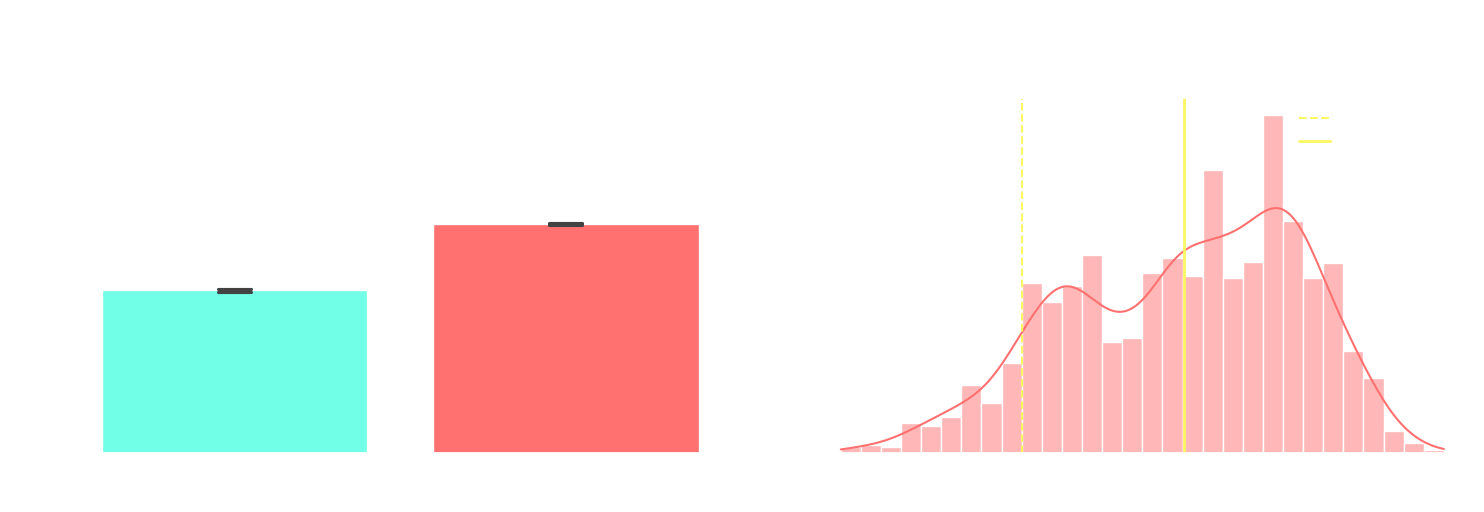

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.font_manager as fm
import seaborn as sns
import numpy as np

font_path = r'C:\Users\hkssn\바탕 화면\multicam\project_db\PretendardVariable.ttf'

if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)
    font_prop = fm.FontProperties(fname=font_path)
    font_name = font_prop.get_name()
    plt.rc('font', family=font_name)
else:
    plt.rc('font', family='Malgun Gothic')

plt.rcParams['axes.unicode_minus'] = False

fig, axes = plt.subplots(1, 2, figsize=(15, 5), facecolor='none')

fig.suptitle('GEO Score 교정 전후 비교 분석', fontsize=16, fontweight='bold', y=1.02, color='white')

# --------------------------------------------------
# 1. 교정 전/후 평균 비교 (Bar Plot)
# --------------------------------------------------
sns.barplot(
    data=pd.melt(df[['score_before', 'score_after']], var_name='Type', value_name='Score'),
    x='Type', y='Score', ax=axes[0], palette=['#71FFE7', '#FF7171'], capsize=0.1, saturation=1.0
)
axes[0].set_facecolor('none')
axes[0].set_title('교정 전/후 평균 점수 비교', fontsize=12, fontweight='bold', color='white')
axes[0].set_xticklabels(['교정 전', '교정 후'], color='white')
axes[0].set_xlabel('', color='white')
axes[0].set_ylabel('GEO Score', color='white')
axes[0].set_ylim(0, 100)

axes[0].text(0, mean_before + 2, f'{mean_before:.2f}점', ha='center', fontweight='bold', color='white')
axes[0].text(1, mean_after + 2, f'{mean_after:.2f}점', ha='center', fontweight='bold', color='white')

# --------------------------------------------------
# 2. 점수 변화량 분포 (Histogram + KDE)
# --------------------------------------------------
sns.histplot(df['score_diff'], kde=True, ax=axes[1], color='#FF7171', bins=30)
axes[1].set_facecolor('none')
axes[1].axvline(0, color='#FAF761', linestyle='--', linewidth=1.5, label='변화 없음 (0)')
axes[1].axvline(mean_diff, color='#FAF761', linestyle='-', linewidth=2, label=f'평균 변화 (+{mean_diff:.2f})')
axes[1].set_title('점수 변화량(Score Diff) 분포', fontsize=12, fontweight='bold', color='white')
axes[1].set_xlabel('점수 변화 (교정 후 - 교정 전)', color='white')
axes[1].set_ylabel('페이지 수', color='white')

leg = axes[1].legend(facecolor='none', edgecolor='none')
for text in leg.get_texts():
    text.set_color('white')

# --------------------------------------------------
# 축, 테두리, 가로 그리드(Y축만) 설정 (세로선 완전 방지)
# --------------------------------------------------
for ax in axes:
    ax.tick_params(colors='white', which='both')
    for spine in ax.spines.values():
        spine.set_edgecolor('white')
    ax.grid(False) # 기존 전체 그리드 초기화
    ax.grid(True, axis='y', linestyle='--', alpha=0.3, color='white') # Y축 가로선만 켜기

plt.tight_layout()
plt.show()

=== 카테고리별 교정 효과 요약 ===
product_cat  sample_count  mean_before  mean_after  mean_diff
         치마           259    43.486486   64.293436  20.806950
         상의          1417    44.656316   64.263232  19.606916
         바지           556    45.944245   64.453237  18.508993
         세트           202    46.920792   64.915842  17.995050
        아우터           526    49.019011   65.169202  16.150190


C:\Users\hkssn\AppData\Local\Temp\ipykernel_6616\3947195945.py:90: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_detail, x='product_cat', y='score_diff', palette='Set3', order=cat_summary['product_cat'])


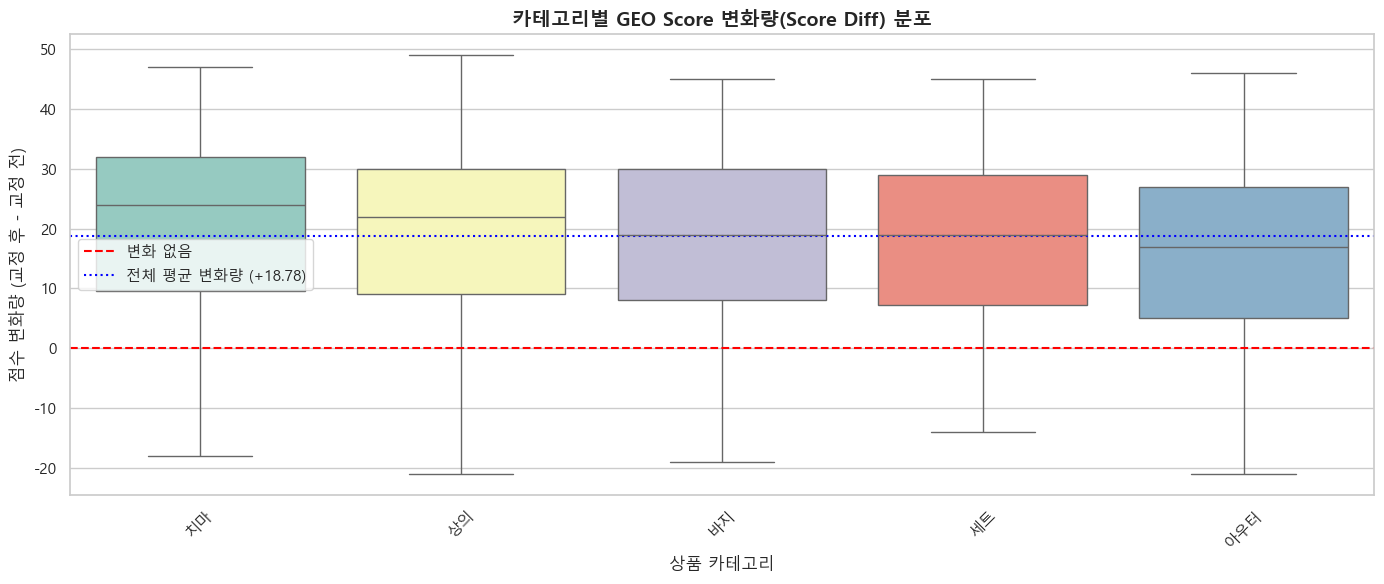

In [ ]:
import os
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.font_manager as fm
import seaborn as sns
import numpy as np

font_path = r'C:\Users\hkssn\바탕 화면\multicam\project_db\PretendardVariable.ttf'

if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)
    font_prop = fm.FontProperties(fname=font_path)
    font_name = font_prop.get_name()
    plt.rc('font', family=font_name)
else:
    plt.rc('font', family='Malgun Gothic')

plt.rcParams['axes.unicode_minus'] = False

plt.rc('font', family='Malgun Gothic')
plt.rc('axes', unicode_minus=False)

query = text("""
    SELECT 
        d.page_id,
        r.product_cat,
        
        -- 전체 점수
        MAX(CASE WHEN d.is_corrected = 0 THEN d.geo_score END) AS score_before,
        MAX(CASE WHEN d.is_corrected = 1 THEN d.geo_score END) AS score_after,
        
        -- 세부 평가 항목별 점수 (교정 전 vs 교정 후)
        MAX(CASE WHEN d.is_corrected = 0 THEN d.text_ratio_score END) AS text_ratio_before,
        MAX(CASE WHEN d.is_corrected = 1 THEN d.text_ratio_score END) AS text_ratio_after,
        
        MAX(CASE WHEN d.is_corrected = 0 THEN d.hybrid_search_score END) AS hybrid_search_before,
        MAX(CASE WHEN d.is_corrected = 1 THEN d.hybrid_search_score END) AS hybrid_search_after,
        
        MAX(CASE WHEN d.is_corrected = 0 THEN d.keyword_stuffing_score END) AS keyword_stuffing_before,
        MAX(CASE WHEN d.is_corrected = 1 THEN d.keyword_stuffing_score END) AS keyword_stuffing_after,
        
        MAX(CASE WHEN d.is_corrected = 0 THEN d.json_ld_score END) AS json_ld_before,
        MAX(CASE WHEN d.is_corrected = 1 THEN d.json_ld_score END) AS json_ld_after,
        
        MAX(CASE WHEN d.is_corrected = 0 THEN d.image_alt_score END) AS image_alt_before,
        MAX(CASE WHEN d.is_corrected = 1 THEN d.image_alt_score END) AS image_alt_after

    FROM diagnosis_table d
    INNER JOIN (
        SELECT DISTINCT page_id 
        FROM diagnosis_table 
        WHERE is_corrected = 1
        and model_ver = '3.2.2'
    ) c ON d.page_id = c.page_id
    INNER JOIN raw_data_table r ON d.page_id = r.page_id
    GROUP BY d.page_id, r.product_cat
    HAVING score_before IS NOT NULL AND score_after IS NOT NULL;
""")

with engine.connect() as conn:
    df_detail = pd.read_sql(query, conn)

df_detail['score_diff'] = df_detail['score_after'] - df_detail['score_before']

sub_features = ['text_ratio', 'hybrid_search', 'keyword_stuffing', 'json_ld', 'image_alt']
for feat in sub_features:
    df_detail[f'{feat}_diff'] = df_detail[f'{feat}_after'] - df_detail[f'{feat}_before']


# ==========================================
# [분석 1] 카테고리별(product_cat) 교정 효과 분석
# ==========================================
cat_summary = df_detail.groupby('product_cat').agg(
    sample_count=('page_id', 'count'),
    mean_before=('score_before', 'mean'),
    mean_after=('score_after', 'mean'),
    mean_diff=('score_diff', 'mean')
).reset_index().sort_values(by='mean_diff', ascending=False)

print("=== 카테고리별 교정 효과 요약 ===")
print(cat_summary.to_string(index=False))

plt.figure(figsize=(14, 6))
sns.boxplot(data=df_detail, x='product_cat', y='score_diff', palette='Set3', order=cat_summary['product_cat'])
plt.axhline(0, color='red', linestyle='--', label='변화 없음')
plt.axhline(df_detail['score_diff'].mean(), color='blue', linestyle=':', label=f'전체 평균 변화량 (+{df_detail["score_diff"].mean():.2f})')
plt.title('카테고리별 GEO Score 변화량(Score Diff) 분포', fontsize=14, fontweight='bold')
plt.xlabel('상품 카테고리')
plt.ylabel('점수 변화량 (교정 후 - 교정 전)')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()


=== 세부 항목별 평균 점수 및 변화량 ===
         feature  before_mean  after_mean  diff_mean
      text_ratio     0.313092    0.999970   0.686878
       image_alt     0.298648    0.564255   0.265607
   hybrid_search     0.291443    0.448841   0.157398
keyword_stuffing     0.752952    0.663986  -0.088965
         json_ld     0.675493    0.551710  -0.123783


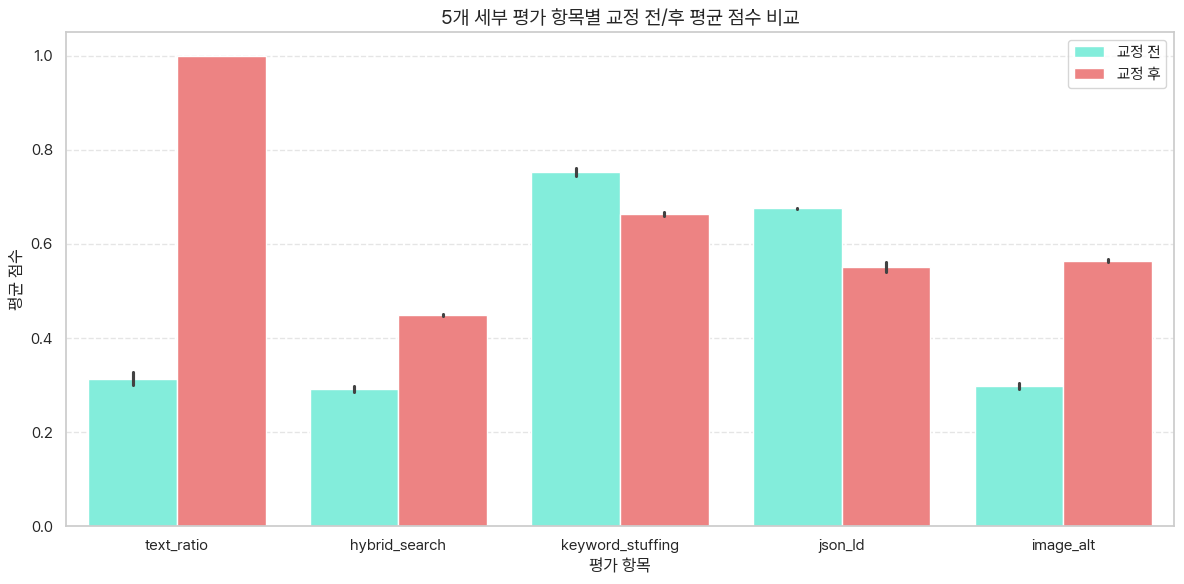

In [ ]:
# ==========================================
# [분석 2] 세부 평가 항목별(Sub-scores) 영향도 분석
# ==========================================

import os
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.font_manager as fm
import seaborn as sns
import numpy as np

font_path = r'C:\Users\hkssn\바탕 화면\multicam\project_db\PretendardVariable.ttf'

if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)
    font_prop = fm.FontProperties(fname=font_path)
    font_name = font_prop.get_name()
    plt.rc('font', family=font_name)
else:
    plt.rc('font', family='Malgun Gothic')

plt.rcParams['axes.unicode_minus'] = False

sub_summary = []
for feat in sub_features:
    before_m = df_detail[f'{feat}_before'].mean()
    after_m = df_detail[f'{feat}_after'].mean()
    diff_m = df_detail[f'{feat}_diff'].mean()
    sub_summary.append({
        'feature': feat,
        'before_mean': before_m,
        'after_mean': after_m,
        'diff_mean': diff_m
    })

df_sub = pd.DataFrame(sub_summary).sort_values(by='diff_mean', ascending=False)

print("\n=== 세부 항목별 평균 점수 및 변화량 ===")
print(df_sub.to_string(index=False))

df_sub_melt = pd.melt(
    df_detail, 
    value_vars=[f'{f}_before' for f in sub_features] + [f'{f}_after' for f in sub_features],
    var_name='feature_type', value_name='score'
)
df_sub_melt['feature'] = df_sub_melt['feature_type'].apply(lambda x: x.rsplit('_', 1)[0])
df_sub_melt['type'] = df_sub_melt['feature_type'].apply(lambda x: '교정 전' if x.endswith('before') else '교정 후')

plt.figure(figsize=(12, 6))
sns.barplot(data=df_sub_melt, x='feature', y='score', hue='type', palette=['#71FFE7', '#FF7171'])
plt.title('5개 세부 평가 항목별 교정 전/후 평균 점수 비교', fontsize=14, fontweight='bold')
plt.xlabel('평가 항목')
plt.ylabel('평균 점수')
plt.legend(title='')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


=== 세부 항목별 평균 점수 및 변화량 ===
         feature  before_mean  after_mean  diff_mean
      text_ratio     0.313092    0.999970   0.686878
       image_alt     0.298648    0.564255   0.265607
   hybrid_search     0.291443    0.448841   0.157398
keyword_stuffing     0.752952    0.663986  -0.088965
         json_ld     0.675493    0.551710  -0.123783


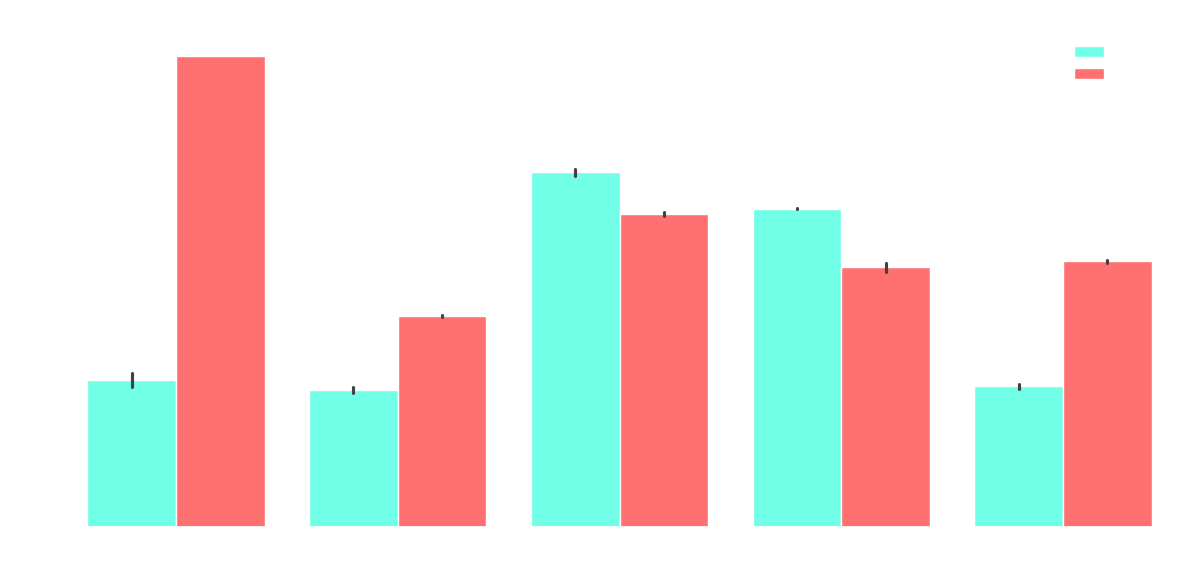

In [ ]:
# ==========================================
# [분석 2] 세부 평가 항목별(Sub-scores) 영향도 분석 (Windows / 배경 투명 / 흰색 텍스트 / 채도 보정)
# ==========================================

import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.font_manager as fm
import seaborn as sns
import numpy as np

font_path = r'C:\Users\hkssn\바탕 화면\multicam\project_db\PretendardVariable.ttf'

if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)
    font_prop = fm.FontProperties(fname=font_path)
    font_name = font_prop.get_name()
    plt.rc('font', family=font_name)
else:
    plt.rc('font', family='Malgun Gothic')

plt.rcParams['axes.unicode_minus'] = False

sub_summary = []
for feat in sub_features:
    before_m = df_detail[f'{feat}_before'].mean()
    after_m = df_detail[f'{feat}_after'].mean()
    diff_m = df_detail[f'{feat}_diff'].mean()
    sub_summary.append({
        'feature': feat,
        'before_mean': before_m,
        'after_mean': after_m,
        'diff_mean': diff_m
    })

df_sub = pd.DataFrame(sub_summary).sort_values(by='diff_mean', ascending=False)

print("\n=== 세부 항목별 평균 점수 및 변화량 ===")
print(df_sub.to_string(index=False))

df_sub_melt = pd.melt(
    df_detail, 
    value_vars=[f'{f}_before' for f in sub_features] + [f'{f}_after' for f in sub_features],
    var_name='feature_type', value_name='score'
)
df_sub_melt['feature'] = df_sub_melt['feature_type'].apply(lambda x: x.rsplit('_', 1)[0])
df_sub_melt['type'] = df_sub_melt['feature_type'].apply(lambda x: '교정 전' if x.endswith('before') else '교정 후')

fig, ax = plt.subplots(figsize=(12, 6), facecolor='none')
ax.set_facecolor('none')

sns.barplot(
    data=df_sub_melt, 
    x='feature', 
    y='score', 
    hue='type', 
    palette=['#71FFE7', '#FF7171'], 
    ax=ax,
    saturation=1.0
)

plt.title('5개 세부 평가 항목별 교정 전/후 평균 점수 비교', fontsize=14, fontweight='bold', color='white')
plt.xlabel('평가 항목', color='white', fontsize=11)
plt.ylabel('평균 점수', color='white', fontsize=11)

ax.tick_params(colors='white', which='both')
for spine in ax.spines.values():
    spine.set_edgecolor('white')

leg = plt.legend(title='', facecolor='none', edgecolor='none')
for text in leg.get_texts():
    text.set_color('white')

plt.grid(axis='y', linestyle='--', alpha=0.3, color='white')
plt.tight_layout()


plt.show()

In [ ]:
group_low = df[df['score_diff'] < 15]
group_high = df[df['score_diff'] >= 15]

print(f"1. 소폭 개선/하락 그룹 (N={len(group_low)}개)")
stat1, p1 = stats.wilcoxon(group_low['score_before'], group_low['score_after'])
print(f"   - 평균 변화량: {group_low['score_diff'].mean():+.2f}점")
print(f"   - Wilcoxon p-value: {p1:.4e}\n")

print(f"2. 대폭 개선 그룹 (N={len(group_high)}개)")
stat2, p2 = stats.wilcoxon(group_high['score_before'], group_high['score_after'])
print(f"   - 평균 변화량: {group_high['score_diff'].mean():+.2f}점")
print(f"   - Wilcoxon p-value: {p2:.4e}")

1. 소폭 개선/하락 그룹 (N=1063개)
   - 평균 변화량: +3.52점
   - Wilcoxon p-value: 9.4634e-51

2. 대폭 개선 그룹 (N=1897개)
   - 평균 변화량: +27.33점
   - Wilcoxon p-value: 0.0000e+00


In [ ]:
np.random.seed(42)
n_iterations = 10000
boot_means = []

for _ in range(n_iterations):
    sample = df['score_diff'].sample(frac=1.0, replace=True)
    boot_means.append(sample.mean())

ci_lower = np.percentile(boot_means, 2.5)
ci_upper = np.percentile(boot_means, 97.5)

print("=== [Bootstrap 95% 신뢰구간 검정] ===")
print(f"평균 변화량 추정치: {np.mean(boot_means):+.2f}점")
print(f"95% 신뢰구간: [{ci_lower:.2f}, {ci_upper:.2f}]")

if ci_lower > 0:
    print("결론: 95% 신뢰구간이 0을 포함하지 않으므로, 분포 형태와 상관없이 교정 효과는 유의미합니다.")

=== [Bootstrap 95% 신뢰구간 검정] ===
평균 변화량 추정치: +18.78점
95% 신뢰구간: [18.30, 19.27]
결론: 95% 신뢰구간이 0을 포함하지 않으므로, 분포 형태와 상관없이 교정 효과는 유의미합니다.


#### 평가 모델 지니계수 차이 검정

In [ ]:
# -------------------------------------------------------------------
# 2. SQL 쿼리 정의 (4개 조건)
# -------------------------------------------------------------------
queries = {
    "v1_pre": """
        SELECT session_id, page_id, sum(is_cited) AS is_cited_cnt, avg(trial_citation_rank) AS citation_rank
        FROM geo_db.eval_log_table
        WHERE session_id LIKE '%%V1%%' AND session_id NOT LIKE '%%POST%%'
        GROUP BY session_id, page_id;
    """,
    "v1_post": """
        SELECT session_id, page_id, sum(is_cited) AS is_cited_cnt, avg(trial_citation_rank) AS citation_rank
        FROM geo_db.eval_log_table
        WHERE session_id LIKE '%%V1%%POST%%'
        GROUP BY session_id, page_id;
    """,
    "v2_pre": """
        SELECT session_id, page_id, sum(is_cited) AS is_cited_cnt, avg(trial_citation_rank) AS citation_rank
        FROM geo_db.eval_log_table
        WHERE session_id LIKE '%%V2%%' AND session_id NOT LIKE '%%POST%%'
        GROUP BY session_id, page_id;
    """,
    "v2_post": """
        SELECT session_id, page_id, sum(is_cited) AS is_cited_cnt, avg(trial_citation_rank) AS citation_rank
        FROM geo_db.eval_log_table
        WHERE session_id LIKE '%%V2%%POST%%'
        GROUP BY session_id, page_id;
    """
}

# -------------------------------------------------------------------
# 3. DB 데이터 로드
# -------------------------------------------------------------------
print("Database에서 데이터를 읽어오는 중입니다...")
dfs = {}
for key, sql in queries.items():
    dfs[key] = pd.read_sql(sql, engine)
    print(f" - {key} 로드 완료: {len(dfs[key]):,} 개 행")

# -------------------------------------------------------------------
# 4. 지니계수 계산 및 부트스트랩 검정 함수
# -------------------------------------------------------------------
def calculate_gini(array):
    """지니계수(Gini Coefficient) 산출"""
    array = np.array(array, dtype=np.float64)
    if np.amin(array) < 0:
        array -= np.amin(array)
    array += 1e-7  # 0 나누기 오류 방지
    array = np.sort(array)
    index = np.arange(1, array.shape[0] + 1)
    n = array.shape[0]
    return ((np.sum((2 * index - n - 1) * array)) / (n * np.sum(array)))

def run_bootstrap_gini_test(group_a, group_b, name_a="Group A", name_b="Group B", num_bootstraps=5000, seed=42):
    """두 집단 간 지니계수 차이에 대한 부트스트랩 검정"""
    np.random.seed(seed)
    
    arr_a = np.array(group_a)
    arr_b = np.array(group_b)
    
    gini_a = calculate_gini(arr_a)
    gini_b = calculate_gini(arr_b)
    obs_diff = gini_b - gini_a
    
    n_a = len(arr_a)
    n_b = len(arr_b)
    
    boot_diffs = []
    for _ in range(num_bootstraps):
        sample_a = np.random.choice(arr_a, size=n_a, replace=True)
        sample_b = np.random.choice(arr_b, size=n_b, replace=True)
        boot_diffs.append(calculate_gini(sample_b) - calculate_gini(sample_a))
        
    boot_diffs = np.array(boot_diffs)
    
    ci_lower = np.percentile(boot_diffs, 2.5)
    ci_upper = np.percentile(boot_diffs, 97.5)
    
    p_value = np.mean(boot_diffs <= 0) if obs_diff > 0 else np.mean(boot_diffs >= 0)
    
    print("\n" + "=" * 60)
    print(f"📊 [{name_a} vs {name_b}] 부트스트랩 지니계수 차이 검정 결과")
    print("=" * 60)
    print(f"• {name_a} 지니계수 : {gini_a:.4f}")
    print(f"• {name_b} 지니계수 : {gini_b:.4f}")
    print(f"• 지니계수 차이 ({name_b} - {name_a}) : {obs_diff:+.4f}")
    print(f"• 95% 신뢰구간 (Confidence Interval) : [{ci_lower:.4f}, {ci_upper:.4f}]")
    print(f"• p-value : {p_value:.5f} " + ("(*** 통계적으로 매우 유의미함)" if p_value < 0.001 else ""))
    print("=" * 60)
    
    return {
        "gini_a": gini_a, "gini_b": gini_b, 
        "diff": obs_diff, "ci": (ci_lower, ci_upper), "p_value": p_value
    }

# -------------------------------------------------------------------
# 5. 검정 실행 (V1 POST vs V2 POST 선택 일관성 비교)
# -------------------------------------------------------------------
v1_post_cnt = dfs["v1_post"]["is_cited_cnt"]
v2_post_cnt = dfs["v2_post"]["is_cited_cnt"]

# V1 POST vs V2 POST 검정 실행 (B=V2, A=V1)
res_v1_vs_v2 = run_bootstrap_gini_test(
    group_a=v1_post_cnt, 
    group_b=v2_post_cnt, 
    name_a="V1 (Strict - 교정 후)", 
    name_b="V2 (Lenient - 교정 후)", 
    num_bootstraps=5000
)

# 필요 시 V2 모델의 교정 전후(V2 PRE vs V2 POST) 변화 검정 실행
res_v2_pre_vs_post = run_bootstrap_gini_test(
    group_a=dfs["v2_pre"]["is_cited_cnt"], 
    group_b=dfs["v2_post"]["is_cited_cnt"], 
    name_a="V2 (교정 전)", 
    name_b="V2 (교정 후)", 
    num_bootstraps=5000
)

Database에서 데이터를 읽어오는 중입니다...
 - v1_pre 로드 완료: 2,740 개 행
 - v1_post 로드 완료: 2,740 개 행
 - v2_pre 로드 완료: 2,740 개 행
 - v2_post 로드 완료: 2,740 개 행

📊 [V1 (Strict - 교정 후) vs V2 (Lenient - 교정 후)] 부트스트랩 지니계수 차이 검정 결과
• V1 (Strict - 교정 후) 지니계수 : 0.5044
• V2 (Lenient - 교정 후) 지니계수 : 0.6718
• 지니계수 차이 (V2 (Lenient - 교정 후) - V1 (Strict - 교정 후)) : +0.1674
• 95% 신뢰구간 (Confidence Interval) : [0.1466, 0.1875]
• p-value : 0.00000 (*** 통계적으로 매우 유의미함)

📊 [V2 (교정 전) vs V2 (교정 후)] 부트스트랩 지니계수 차이 검정 결과
• V2 (교정 전) 지니계수 : 0.7259
• V2 (교정 후) 지니계수 : 0.6718
• 지니계수 차이 (V2 (교정 후) - V2 (교정 전)) : -0.0541
• 95% 신뢰구간 (Confidence Interval) : [-0.0742, -0.0335]
• p-value : 0.00000 (*** 통계적으로 매우 유의미함)
